# PSI3442 — P2 — Sistema de Missões Autônomas: modelo SysML 2.0 (níveis 0, 1 e n)

As células de código abaixo são cópias dos arquivos `*.sysml` desta pasta. Edite os arquivos e rode `python executar_modelo.py --so-gerar` para atualizar o notebook. Execute tudo com *Run → Run All Cells*.

## `00_Comum.sysml`

In [1]:
package Comum {
    doc /* Tipos, tópicos ROS 2, sinais, portas e requisitos compartilhados pelos níveis 0, 1 e n.
           PSI3442 — P2 2026 — Sistema de Missões Autônomas com DJI Mini 4 Pro:
           Tarefa 1 = voo de familiarização (Questão 1); Tarefa 2 = balões (Questão 2). */

    private import ScalarValues::*;
    private import ISQ::*;
    private import SI::*;

    // ------------------------------------------------------------------ grandezas físicas e energia
    item def Energia { doc /* Energia elétrica fornecida por bateria ou fonte. */ }
    item def Empuxo { doc /* Força e torque aplicados ao ar pelas hélices. */ }
    item def SinalVisual { doc /* Indicação luminosa (LEDs de status). */ }
    item def AcaoManual { doc /* Ação física do operador: ligar/desligar, trocar bateria, posicionar a aeronave. */ }
    item def GrandezaFisica { doc /* Grandeza do ambiente percebida por um sensor. */ }
    item def Distancia :> GrandezaFisica;
    item def Pressao :> GrandezaFisica;
    item def TexturaIluminacao :> GrandezaFisica { doc /* Textura do piso e iluminação: condição para o posicionamento visual. */ }
    item def Imagem :> GrandezaFisica;
    item def SinalGNSS :> GrandezaFisica { doc /* Indisponível em ambiente interno (R07): não utilizado. */ }

    // ------------------------------------------------------------------ referencial e dados
    attribute def ReferencialLocal {
        doc /* Referencial local da Tarefa 1 (P02), dextrogiro:
               origem = ponto de decolagem no piso (A projetado no piso);
               x = horizontal de A para B (direção do nariz da aeronave na decolagem, guinada psi0);
               y = horizontal de A para D (à esquerda do nariz);
               z = vertical para cima, medida do piso ao ponto de referência da aeronave (P01).
               Conversão a partir da telemetria (norte, leste, baixo):
               x =  N cos(psi0) + E sin(psi0);  y = N sin(psi0) - E cos(psi0);  vz = -vBaixo. */
        attribute guinadaDecolagem : Real;
    }

    attribute def Ponto3D {
        doc /* Coordenadas no ReferencialLocal. */
        attribute x : LengthValue;
        attribute y : LengthValue;
        attribute z : LengthValue;
    }

    enum def SentidoPercurso {
        doc /* Com x para B, y para D e z para cima, A-B-C-D é anti-horário visto de cima. */
        enum abcd;   // A -> B -> C -> D -> A
        enum adcb;   // A -> D -> C -> B -> A
    }

    enum def AcaoOperador {
        doc /* Únicos comandos do operador: não há pilotagem (R03). */
        enum executarTarefa1;
        enum executarTarefa2;
        enum interromper;
    }

    enum def TipoComando {
        enum decolar;
        enum pousar;
        enum habilitarControleVirtual;
        enum desabilitarControleVirtual;
        enum pararEPairar;
    }

    enum def TipoFalha {
        enum perdaEnlace;
        enum perdaPonte;
        enum telemetriaAtrasada;
        enum bateriaBaixa;
        enum estimativaInvalida;
        enum posicionamentoVisualInativo;
        enum desvioExcessivo;
        enum tempoTarefaExcedido;
        enum comandoRejeitado;
    }

    item def Telemetria {
        doc /* Amostra publicada pelo drone (caixa-preta), lida pelo app ponte via DJI Mobile SDK e republicada em
               /dji/telemetria. Velocidades no referencial do solo (norte, leste, baixo); altura relativa à decolagem. */
        attribute instante : DurationValue;
        attribute vNorte : SpeedValue;
        attribute vLeste : SpeedValue;
        attribute vBaixo : SpeedValue;
        attribute altitude : LengthValue;
        attribute alturaToF : LengthValue;
        attribute guinada : Real;
        attribute emVoo : Boolean;
        attribute motoresLigados : Boolean;
        attribute modoVoo : String;
        attribute bateriaPercentual : Real;
        attribute conectado : Boolean;
        attribute posicionamentoVisualAtivo : Boolean;
        attribute controleVirtualAtivo : Boolean;   // confirma a preparação por leitura
        attribute acaoPerdaSinal : String;          // idem: deve ser "pousar"
    }

    item def EstadoEstimado {
        doc /* Estado da aeronave no ReferencialLocal (tópico /estado). */
        attribute posicao : Ponto3D;
        attribute vx : SpeedValue;
        attribute vy : SpeedValue;
        attribute vz : SpeedValue;
        attribute valido : Boolean;
        attribute psi0 : Real;                      // guinada registrada na borda de subida de motoresLigados
        attribute motivoInvalido : String;
    }

    attribute def VereditoTolerancia {
        attribute dentroHorizontal : Boolean;
        attribute dentroVertical : Boolean;
        attribute dentroVelocidade : Boolean;
        attribute dentro : Boolean;
    }

    item def Setpoint {
        attribute ponto : Ponto3D;
        attribute ativo : Boolean;    // falso durante a decolagem e o pouso automáticos
    }

    item def ComandoVelocidade {
        doc /* Velocidade comandada (tópico /dji/cmd_vel) no ReferencialLocal; o app ponte converte para o solo. */
        attribute vx : SpeedValue;
        attribute vy : SpeedValue;
        attribute vz : SpeedValue;
        attribute taxaGuinada : Real;
        attribute psi0 : Real;        // para o app ponte converter ao referencial do solo
    }

    item def ComandoDiscreto { attribute tipo : TipoComando; }
    item def ComandoOperador { attribute acao : AcaoOperador; }
    item def TarefaAtiva { attribute numero : Integer; }
    item def StatusTarefa { doc /* Estado da tarefa, vértice/alvo atual, cronômetro, falhas, telemetria resumida:
                                   alimenta o painel e o CSV. */ }
    item def EventoTarefa {
        doc /* Início, permanência concluída, conclusão ou aborto de tarefa; também SOLICITA_ACAO: a tarefa pede
               decolar/pousar ao gerenciador, único que publica em /dji/acao. */
    }
    item def Falha { attribute tipo : TipoFalha; }
    item def Alvos { doc /* Questão 2: balões detectados, cor, posição na imagem e distância estimada. */ }
    item def Obstaculos {
        doc /* Distâncias aos obstáculos por setor em torno da aeronave, lidas pelo app ponte (PerceptionManager do SDK —
               verificar disponibilidade no Mini 4 Pro) e republicadas em /dji/obstaculos. */
        attribute distancias : LengthValue[*];
    }
    item def MapaLocal {
        doc /* Mapa grosseiro no ReferencialLocal (tópico /mapa): grade 2D de ocupação de baixa resolução e lista de
               balões com cor, posição estimada e incerteza. Serve para localizar os balões no espaço relativo à
               decolagem, não para navegação precisa. */
        attribute resolucao : LengthValue;
    }
    item def QuadroCamera :> Imagem { doc /* Quadro de vídeo da câmera principal (tópico /dji/camera). */ }
    item def RegistroLog { doc /* Registro: bag do rosbag2 e CSV exportado. */ }
    item def PacoteDados { doc /* Mensagem serializada trafegando por TCP, USB ou RF. */ }

    item def ConfiguracaoTarefa1 {
        doc /* Parâmetros da Tarefa 1 no arquivo de configuração (YAML). */
        attribute vertices : Ponto3D[4];
        attribute sentido : SentidoPercurso;
        attribute alturaAlvo : LengthValue;
        attribute aresta : LengthValue;
        attribute tempoPermanencia : DurationValue;
        attribute tolHorizontal : LengthValue;
        attribute tolVertical : LengthValue;
        attribute vPairadoMax : SpeedValue;
        attribute vToqueMax : SpeedValue;
        attribute vDeslocamentoMax : SpeedValue;
        attribute bateriaMinimaPercentual : Real;      // condição para iniciar
        attribute bateriaCriticaPercentual : Real;     // em voo: abaixo disto, término seguro
        attribute tempoMaxTarefa : DurationValue;
        attribute tempoEstabilizacao : DurationValue;
        attribute alturaMinDecolagem : LengthValue;    // DecolagemConcluida exige z acima disto
        attribute tempoMaxPreparacao : DurationValue;
        attribute tempoMaxDecolagem : DurationValue;
        attribute persistenciaFalha : DurationValue;   // telemetria atrasada ou estimativa inválida
    }

    item def ConfiguracaoTarefa2 {
        doc /* Parâmetros da Tarefa 2 (R01) — a detalhar. */
        attribute coresAlvo : String[*];
        attribute distanciaMaxima : LengthValue;
        attribute tempoPermanencia : DurationValue;
        attribute margemObstaculos : LengthValue;
    }

    item def ConfiguracaoTarefas {
        item tarefa1 : ConfiguracaoTarefa1;
        item tarefa2 : ConfiguracaoTarefa2;
    }

    // ------------------------------------------------------------------ sinais das máquinas de estados
    attribute def ExecutarTarefa1 { doc /* Operador envia "executar tarefa 1". */ }
    attribute def ExecutarTarefa2 { doc /* Operador envia "executar tarefa 2". */ }
    attribute def InterromperTarefa { doc /* Operador envia "interromper". */ }
    attribute def TarefaConcluida { doc /* Tarefa terminou e a aeronave está pousada. */ }
    attribute def PreparacaoConcluida {
        doc /* Ponte conectada, aeronave conectada, bateria >= mínimo, posicionamento visual ativo, ação de perda de
               sinal = pousar confirmada por leitura, controle virtual habilitado e guinada psi0 registrada. */
    }
    attribute def DecolagemConcluida { doc /* emVoo = true e |vz| <= vPairadoMax após o comando de decolagem automática. */ }
    attribute def AlturaAtingida { doc /* |z - alturaAlvo| <= tolVertical e |v| <= vPairadoMax. */ }
    attribute def VerticeAtingido { doc /* Veredito "dentro" no setpoint atual (erro horizontal, vertical e velocidade). */ }
    attribute def ToleranciaExcedida { doc /* Veredito passa de "dentro" para "fora" durante a permanência: zera o cronômetro (P05). */ }
    attribute def PermanenciaConcluida { doc /* Cronômetro atinge tempoPermanencia contínuo em tempo real. */ }
    attribute def Estabilizado { doc /* Veredito "dentro" em A (retorno) mantido por tempoEstabilizacao. */ }
    attribute def PousoConfirmado { doc /* Telemetria: emVoo = false e motoresLigados = false. */ }
    attribute def FalhaDetectada {
        doc /* Publicada em /falhas pela supervisão, ou pela ponte (comando rejeitado pelo SDK, perda da ponte). */
        attribute tipo : TipoFalha;
    }

    // ------------------------------------------------------------------ portas físicas e de comunicação
    port def PortaEnergia { in item energia : Energia; }
    port def PortaAcaoManual { in item acao : AcaoManual; }
    port def PortaSensorial { in item grandeza : GrandezaFisica; }
    port def PortaEmpuxo { out item empuxo : Empuxo; }
    port def PortaSinalVisual { out item sinal : SinalVisual; }
    port def PortaRF { inout item pacote : PacoteDados; }
    port def PortaUSB { inout item pacote : PacoteDados; }
    port def PortaSocket { doc /* TCP pelo Wi-Fi entre o notebook e o celular (nos testes sem drone: adb forward para o Android emulado). */ inout item pacote : PacoteDados; }
    port def PortaConfiguracao { in item config : ConfiguracaoTarefas; }
    port def PortaLogs { out item registro : RegistroLog; }
    port def PortaPainel { out item status : StatusTarefa; }
    port def PortaOperador { in item comando : ComandoOperador; }

    // ------------------------------------------------------------------ tópicos ROS 2 (quem publica usa a porta; quem assina, a conjugada)
    port def TopicoComandoOperador { attribute nome : String = "/operador/comando"; out item msg : ComandoOperador; }
    port def TopicoTarefaAtiva { attribute nome : String = "/tarefa/ativa"; out item msg : TarefaAtiva; }
    port def TopicoTarefaStatus { attribute nome : String = "/tarefa/status"; out item msg : StatusTarefa; }
    port def TopicoTarefaEvento { attribute nome : String = "/tarefa/evento"; out item msg : EventoTarefa; }
    port def TopicoAcaoDJI { attribute nome : String = "/dji/acao"; out item msg : ComandoDiscreto; }
    port def TopicoSetpoint { attribute nome : String = "/setpoint"; out item msg : Setpoint; }
    port def TopicoEstado { attribute nome : String = "/estado"; out item msg : EstadoEstimado; }
    port def TopicoAlvos { attribute nome : String = "/alvos"; out item msg : Alvos; }
    port def TopicoObstaculos { attribute nome : String = "/dji/obstaculos"; out item msg : Obstaculos; }
    port def TopicoMapa { attribute nome : String = "/mapa"; out item msg : MapaLocal; }
    port def TopicoCmdVel { attribute nome : String = "/dji/cmd_vel"; out item msg : ComandoVelocidade; }
    port def TopicoTelemetria { attribute nome : String = "/dji/telemetria"; out item msg : Telemetria; }
    port def TopicoCamera { attribute nome : String = "/dji/camera"; out item msg : QuadroCamera; }
    port def TopicoFalhas { attribute nome : String = "/falhas"; out item msg : Falha; }

    // ------------------------------------------------------------------ requisitos da Questão 1 (Tarefa 1)
    package RequisitosQ1 {
        requirement def <P01> Decolagem {
            doc /* Decolar verticalmente a partir do ponto inicial e atingir 1,80 m de altura em relação ao piso.
                   Ponto de referência geométrico declarado: plano inferior do corpo da aeronave (sensores inferiores),
                   mantido em todas as medições. */
            subject sujeito;
            attribute alturaAlvo : LengthValue = 1.80 [m];
            attribute alturaMedida : LengthValue;
            attribute tolVertical : LengthValue;
            require constraint { alturaMedida - alturaAlvo <= tolVertical and alturaAlvo - alturaMedida <= tolVertical }
        }

        requirement def <P02> QuadradoHorizontal {
            doc /* Percorrer um quadrado horizontal de aresta 1,50 m a 1,80 m de altura:
                   A=(0;0;1,80) B=(1,50;0;1,80) C=(1,50;1,50;1,80) D=(0;1,50;1,80), A acima do ponto de decolagem. */
            subject sujeito;
            attribute aresta : LengthValue = 1.50 [m];
            attribute alturaAlvo : LengthValue = 1.80 [m];
        }

        requirement def <P03> PermanenciaNosVertices {
            doc /* Pairar pelo menos 60 s contínuos em A, B, C e D, nesta ordem (ou A, D, C, B); sem segunda espera em A. */
            subject sujeito;
            attribute tempoPermanencia : DurationValue = 60 [s];
            attribute tempoMedido : DurationValue;
            require constraint { tempoMedido >= tempoPermanencia }
        }

        requirement def <P04> PousoSuave {
            doc /* Retornar ao ponto inicial e pousar com redução controlada da velocidade vertical;
                   encerrar após confirmar o pouso por telemetria. */
            subject sujeito;
            attribute vToqueMax : SpeedValue;
            attribute vToqueMedida : SpeedValue;
            require constraint { vToqueMedida <= vToqueMax }
        }

        requirement def <P05> ToleranciasDeclaradas {
            doc /* Tolerâncias de posição e altura, limites de velocidade de voo pairado e de toque, definidos antes dos
                   testes e aprovados na entrega intermediária; a contagem de permanência reinicia se forem excedidas. */
            subject sujeito;
        }

        requirement def <P06> EvidenciaEModelo {
            doc /* Modelo SysML 2.0 (níveis 0, 1 e n), implementação executável, configuração da trajetória, logs e
                   evidências em voo real; estados de decolagem, deslocamento, permanência, retorno, pouso e falha. */
            subject sujeito;
        }

        requirement def <R07> FalhasEmAmbienteInterno {
            doc /* Comum às duas tarefas. Tratar perda de comunicação, bateria insuficiente, estimativa inválida e tempo
                   excedido com término seguro adequado a uma sala. Retorno automático por GNSS não é solução válida. */
            subject sujeito;
        }
    }

    // ------------------------------------------------------------------ requisitos da Questão 2 (Tarefa 2)
    package RequisitosQ2 {
        requirement def <R01> Configuracao { doc /* Carregar cores-alvo, limites de tempo, condições iniciais e parâmetros de arquivo documentado. */ subject sujeito; }
        requirement def <R02> Percepcao { doc /* Detectar e classificar balões nas imagens da câmera do drone em voo real. */ subject sujeito; }
        requirement def <R03> Autonomia {
            doc /* Busca, seleção, aproximação, confirmação, afastamento e próximo alvo; o operador só inicia e interrompe. */
            subject sujeito;
        }
        requirement def <R04> DistanciaEPermanencia {
            doc /* 0 < d <= 0,05 m entre a bexiga e o envelope externo (com hélices) por 60 s contínuos, sem colisão;
                   método de medição e incerteza; contagem reinicia ao sair da faixa. */
            subject sujeito;
            attribute distanciaMaxima : LengthValue = 0.05 [m];
            attribute tempoPermanencia : DurationValue = 60 [s];
        }
        requirement def <R05> Estimacao { doc /* Estimar a distância com as observações disponíveis; referência independente não alimenta o algoritmo. */ subject sujeito; }
        requirement def <R06> Restricoes { doc /* Evitar paredes, teto, piso, mobiliário e bexigas não selecionadas, com margens definidas. */ subject sujeito; }
        requirement def <R08> Observabilidade { doc /* Painel com estado, alvo, distância, tempo, eventos e falhas; logs exportáveis. */ subject sujeito; }
        requirement def <R09> Reprodutibilidade { doc /* Execução documentada em outro computador, com dependências, versões, parâmetros e sementes. */ subject sujeito; }
    }
}


Package Comum (fdb4b0c2-5b6c-4786-b2b2-82de98de5378)


## `01_Nivel0.sysml`

In [2]:
package Nivel0 {
    doc /* Nível 0 — Sistema de Missões Autônomas: sistema de interesse, atores externos, cenário de operação,
           fronteiras, entradas, saídas e fluxos de informação e energia. Corresponde a diagramas/nivel_0.png.

           Paradigma: o drone é um produto dado; o trabalho é de software. A lógica das tarefas roda em nós ROS 2 num
           notebook Linux; um celular (ou tablet) Android executa o app ponte com o DJI Mobile SDK v5 e conversa com o
           notebook pelo Wi-Fi; o rádio DJI (RC-N2/N3) é apenas o enlace exigido pelo SDK (seção 6 do enunciado), sem
           pilotagem; o drone é um componente caixa-preta. O celular é necessário porque o SDK fala com o rádio pelo
           modo acessório USB do Android (o rádio é o hospedeiro USB), papel que a porta USB do notebook não cumpre;
           um Android emulado no notebook serve só como ambiente de teste sem drone. O operador só comanda "executar tarefa 1", "executar tarefa 2" ou "interromper".

           Diferenças em relação aos modelos anteriores (P1 e primeira versão desta prova, com celular):
           - estação de solo substituída por notebook Linux + ROS 2; o celular só executa o app ponte (tradutor);
           - controle remoto rebaixado a rádio-enlace; nenhuma entrada de pilotagem;
           - drone deixa de ser decomposto em blocos internos: é tratado só pelas entradas e saídas;
           - GPS mantido só como entrada indisponível (R07); textura do piso e iluminação como entrada do ambiente;
           - botão Reset removido (não existe no Mini 4 Pro); USB e cartão de memória da aeronave não participam
             das tarefas e saíram da fronteira. */

    private import Comum::*;
    private import Comum::RequisitosQ1::*;
    private import Comum::RequisitosQ2::*;

    // ------------------------------------------------------------------ elementos externos
    part def Operador {
        doc /* Ator externo: comanda tarefas; não pilota. */
        port comando : ~PortaOperador;
        port painel : ~PortaPainel;
        port acaoManual : ~PortaAcaoManual;
        port leds : ~PortaSinalVisual;
    }

    part def AmbienteFisico {
        doc /* Sala de aula: piso (textura), paredes, teto, mobiliário, iluminação, ar e balões estáticos (Tarefa 2). */
        port distancia : ~PortaSensorial;
        port pressao : ~PortaSensorial;
        port texturaIluminacao : ~PortaSensorial;
        port imagem : ~PortaSensorial;
        port empuxo : ~PortaEmpuxo;
    }

    part def FonteEnergia {
        doc /* Alimentação do notebook e baterias carregadas do celular, do rádio e da aeronave. */
        port notebook : ~PortaEnergia;
        port celular : ~PortaEnergia;
        port radio : ~PortaEnergia;
        port aeronave : ~PortaEnergia;
    }

    part def ArquivoConfiguracao {
        doc /* YAML com os parâmetros das tarefas (P05, R01). */
        port saida : ~PortaConfiguracao;
    }

    part def RepositorioLogs {
        doc /* Destino dos logs exportáveis (rosbag2 e CSV) usados como evidência (P06, R08). */
        port entrada : ~PortaLogs;
    }

    part def SatelitesGNSS {
        doc /* Indisponíveis em ambiente interno: representados para registrar que não são usados (R07). */
        port sinal : ~PortaSensorial;
    }

    part def Simulador {
        doc /* Opcional — ambiente de teste. Substitui ponte, rádio e drone publicando e assinando os mesmos tópicos
               /dji/* do nó ponte; a lógica das tarefas roda sem alteração. Resultados identificados separadamente,
               com a escala de tempo usada (P06). Implementados: simulador cinemático, Gazebo e o Android emulado com
               o app ponte e um drone falso (android_ponte, variante emulador). */
        port socket : PortaSocket;
    }

    // ------------------------------------------------------------------ componentes do sistema
    part def AplicacaoROS2 {
        doc /* Nós ROS 2 com toda a lógica das tarefas (decomposta no nível 1). */
        port comandosOperador : PortaOperador;
        port painel : PortaPainel;
        port config : PortaConfiguracao;
        port logs : PortaLogs;
        port socketPonte : PortaSocket;
    }

    part def DispositivoMovel {
        doc /* Celular ou tablet Android (ARM64, Android 7+) com o app ponte e o DJI Mobile SDK v5. Ligado ao rádio por
               cabo USB (rádio = hospedeiro, celular = acessório) e ao notebook pelo Wi-Fi. Precisa de internet na
               primeira execução para registrar a App Key. */
        port socketPonte : PortaSocket;
        port usb : PortaUSB;
        port bateria : PortaEnergia;
    }

    part def NotebookLinux {
        port comandosOperador : PortaOperador;
        port painel : PortaPainel;
        port config : PortaConfiguracao;
        port logs : PortaLogs;
        port wifi : PortaSocket;
        port energia : PortaEnergia;

        part ros2 : AplicacaoROS2;

        connect ros2.socketPonte to wifi;
        connect comandosOperador to ros2.comandosOperador;
        connect ros2.painel to painel;
        connect config to ros2.config;
        connect ros2.logs to logs;
    }

    part def RadioDJI {
        doc /* Controle remoto compatível com o Mobile SDK v5 para o Mini 4 Pro: DJI RC N2 ou RC N3 (SDK >= 5.13.0;
               DJI RC 2 não suportado). Indispensável: não há conexão direta celular-aeronave documentada para este
               modelo. Usado só como rádio-enlace: nenhum comando de pilotagem sai dele. */
        port usb : PortaUSB;
        port rf : PortaRF;
        port bateria : PortaEnergia;
    }

    part def Drone {
        doc /* DJI Mini 4 Pro — produto comercial tratado como caixa-preta: estabilização, sensores, atuadores e
               energia ficam no firmware DJI. */
        port bateria : PortaEnergia;
        port botaoOnOff : PortaAcaoManual;
        port distancia : PortaSensorial;
        port pressao : PortaSensorial;
        port texturaIluminacao : PortaSensorial;
        port imagem : PortaSensorial;
        port gps : PortaSensorial { doc /* Indisponível indoor. */ }
        port empuxo : PortaEmpuxo;
        port ledReady : PortaSinalVisual;
        port rf : PortaRF;
    }

    part def SistemaMissoesAutonomas {
        doc /* Função global: ao receber "executar tarefa N", realizar a tarefa N de forma autônoma até o pouso
               (Tarefa 1: quadrado de 1,50 m a 1,80 m com quatro permanências de 60 s; Tarefa 2: balões), respeitando
               tolerâncias e restrições e registrando evidências; interromper com segurança quando comandado. */
        part notebook : NotebookLinux;
        part celular : DispositivoMovel;
        part radio : RadioDJI;
        part drone : Drone;
        flow of PacoteDados from notebook.wifi.pacote to celular.socketPonte.pacote;
        flow of PacoteDados from celular.socketPonte.pacote to notebook.wifi.pacote;
        flow of PacoteDados from celular.usb.pacote to radio.usb.pacote;
        flow of PacoteDados from radio.usb.pacote to celular.usb.pacote;
        flow of PacoteDados from radio.rf.pacote to drone.rf.pacote;
        flow of PacoteDados from drone.rf.pacote to radio.rf.pacote;
    }

    part def ContextoOperacional {
        part operador : Operador;
        part ambiente : AmbienteFisico;
        part energia : FonteEnergia;
        part arquivoConfig : ArquivoConfiguracao;
        part repositorioLogs : RepositorioLogs;
        part gnss : SatelitesGNSS;
        part sistema : SistemaMissoesAutonomas;

        // informação
        flow of ComandoOperador from operador.comando.comando to sistema.notebook.comandosOperador.comando;
        flow of StatusTarefa from sistema.notebook.painel.status to operador.painel.status;
        flow of ConfiguracaoTarefas from arquivoConfig.saida.config to sistema.notebook.config.config;
        flow of RegistroLog from sistema.notebook.logs.registro to repositorioLogs.entrada.registro;
        flow of SinalVisual from sistema.drone.ledReady.sinal to operador.leds.sinal;
        flow of AcaoManual from operador.acaoManual.acao to sistema.drone.botaoOnOff.acao;

        // grandezas físicas sensoriadas
        flow of Distancia from ambiente.distancia.grandeza to sistema.drone.distancia.grandeza;
        flow of Pressao from ambiente.pressao.grandeza to sistema.drone.pressao.grandeza;
        flow of TexturaIluminacao from ambiente.texturaIluminacao.grandeza to sistema.drone.texturaIluminacao.grandeza;
        flow of Imagem from ambiente.imagem.grandeza to sistema.drone.imagem.grandeza;
        flow of SinalGNSS from gnss.sinal.grandeza to sistema.drone.gps.grandeza;

        // energia e força
        flow of Energia from energia.notebook.energia to sistema.notebook.energia.energia;
        flow of Energia from energia.celular.energia to sistema.celular.bateria.energia;
        flow of Energia from energia.radio.energia to sistema.radio.bateria.energia;
        flow of Energia from energia.aeronave.energia to sistema.drone.bateria.energia;
        flow of Empuxo from sistema.drone.empuxo.empuxo to ambiente.empuxo.empuxo;
    }

    part contexto : ContextoOperacional;

    // ------------------------------------------------------------------ cenário de operação
    use case def CenarioOperacao {
        doc /* Cenário de operação de uma tarefa na sala de aula. */
        subject sistema : SistemaMissoesAutonomas;
        actor operador : Operador;
        objective { doc /* Executar a tarefa pedida de forma autônoma, com o operador apenas comandando a tarefa. */ }

        action prepararAmbiente {
            doc /* Tarefa 1: marcar A, B, C e D no piso; Tarefa 2: posicionar os balões. Piso texturizado, iluminação
                   e volume livre com margem de segurança (hipótese: 2,5 m x 2,5 m x 2,5 m para a Tarefa 1). */
        }
        action posicionarAeronave { doc /* Aeronave sobre A, nariz apontado para B (define psi0). */ }
        action ligarEquipamentos {
            doc /* Ligar aeronave e rádio; ligar o celular ao rádio pelo cabo e abrir o app ponte; celular e notebook na
                   mesma rede Wi-Fi; lançar os nós ROS 2 com o IP do celular. */
        }
        action carregarConfiguracao { doc /* Gerenciador carrega o YAML aprovado; o painel exibe os parâmetros. */ }
        action comandarTarefa { doc /* Operador envia "executar tarefa 1" (ou 2). A partir daqui nada é pilotado. */ }
        action executarTarefa {
            doc /* Execução autônoma até o pouso. O operador pode enviar "interromper" (pouso no local). */
        }
        action exportarEvidencias { doc /* Exportar o rosbag2/CSV da tarefa e o vídeo da demonstração. */ }

        first start then prepararAmbiente;
        first prepararAmbiente then posicionarAeronave;
        first posicionarAeronave then ligarEquipamentos;
        first ligarEquipamentos then carregarConfiguracao;
        first carregarConfiguracao then comandarTarefa;
        first comandarTarefa then executarTarefa;
        first executarTarefa then exportarEvidencias;
        first exportarEvidencias then done;
    }

    // ------------------------------------------------------------------ requisitos alocados ao sistema
    requirement p01 : Decolagem;
    requirement p02 : QuadradoHorizontal;
    requirement p03 : PermanenciaNosVertices;
    requirement p04 : PousoSuave;
    requirement p05 : ToleranciasDeclaradas;
    requirement p06 : EvidenciaEModelo;
    requirement r07 : FalhasEmAmbienteInterno;
    requirement r01 : Configuracao;
    requirement r02 : Percepcao;
    requirement r03 : Autonomia;
    requirement r04 : DistanciaEPermanencia;
    requirement r05 : Estimacao;
    requirement r06 : Restricoes;
    requirement r08 : Observabilidade;
    requirement r09 : Reprodutibilidade;

    satisfy p01 by contexto.sistema;
    satisfy p02 by contexto.sistema;
    satisfy p03 by contexto.sistema;
    satisfy p04 by contexto.sistema;
    satisfy p05 by contexto.sistema;
    satisfy p06 by contexto.sistema;
    satisfy r07 by contexto.sistema;
    satisfy r01 by contexto.sistema;
    satisfy r02 by contexto.sistema;
    satisfy r03 by contexto.sistema;
    satisfy r04 by contexto.sistema;
    satisfy r05 by contexto.sistema;
    satisfy r06 by contexto.sistema;
    satisfy r08 by contexto.sistema;
    satisfy r09 by contexto.sistema;
}


Package Nivel0 (7ffe584a-6888-48a2-8236-46ab0cfb130c)


## `02_Nivel1.sysml`

In [3]:
package Nivel1 {
    doc /* Nível 1 — decomposição funcional do Sistema de Missões Autônomas (diagramas/nivel_1.png).
           Alvo da decomposição: as tarefas e os serviços ROS 2 que elas usam. Celular, rádio DJI e drone
           permanecem componentes caixa-preta de comunicação e execução.
           Reuso entre as tarefas: gerenciador, estimação, controle, supervisão, registro e ponte DJI são comuns;
           só a Tarefa 2 usa a visão computacional e o mapeamento local. */

    private import ScalarValues::*;
    private import Comum::*;
    private import Nivel0::*;

    // ------------------------------------------------------------------ nós ROS 2
    part def InterfaceOperador {
        doc /* Recebe "executar tarefa 1", "executar tarefa 2" ou "interromper" e mostra o painel. */
        port operador : PortaOperador;
        port painel : PortaPainel;
        port pubComando : TopicoComandoOperador;
        port subStatus : ~TopicoTarefaStatus;
        port subFalhas : ~TopicoFalhas;
    }

    part def GerenciadorTarefas {
        doc /* Carrega a configuração, ativa a tarefa pedida, mantém os modos globais e é o único que publica em
               /dji/acao (decolar/pousar pedidos pela tarefa via SOLICITA_ACAO). Repassa as falhas à tarefa publicando
               /tarefa/ativa = 0 e comandando o pouso. Assina telemetria e estado para aceitar comandos, montar o
               painel e encerrar o término seguro. */
        port config : PortaConfiguracao;
        port subComando : ~TopicoComandoOperador;
        port subTelemetria : ~TopicoTelemetria;
        port subEstado : ~TopicoEstado;
        port subEvento : ~TopicoTarefaEvento;
        port subFalhas : ~TopicoFalhas;
        port pubAtiva : TopicoTarefaAtiva;
        port pubStatus : TopicoTarefaStatus;
        port pubAcao : TopicoAcaoDJI;
        exhibit state modos : ModosOperacao;
    }

    part def Tarefa1VooFamiliarizacao {
        doc /* Questão 1: quadrado A-B-C-D a 1,80 m, quatro permanências de 60 s, retorno e pouso. Assina a
               telemetria para as checagens da preparação e para emVoo/motoresLigados na decolagem e no pouso. */
        port subAtiva : ~TopicoTarefaAtiva;
        port subEstado : ~TopicoEstado;
        port subTelemetria : ~TopicoTelemetria;
        port pubSetpoint : TopicoSetpoint;
        port pubEvento : TopicoTarefaEvento;
    }

    part def Tarefa2Baloes {
        doc /* Questão 2: busca, seleção, aproximação a 0 < d <= 5 cm por 60 s, afastamento, próximo alvo. */
        port subAtiva : ~TopicoTarefaAtiva;
        port subEstado : ~TopicoEstado;
        port subAlvos : ~TopicoAlvos;
        port subMapa : ~TopicoMapa;
        port pubSetpoint : TopicoSetpoint;
        port pubEvento : TopicoTarefaEvento;
    }

    part def MapeamentoLocal {
        doc /* Só na Tarefa 2. Mapa grosseiro para localizar os balões no espaço relativo: projeta as detecções
               (direção e distância vindas da percepção) a partir da pose estimada para obter a posição de cada balão
               no ReferencialLocal, e marca numa grade 2D de baixa resolução os obstáculos vistos pelos sensores da
               aeronave. A incerteza cresce com a deriva da estimação de estado; o mapa é relativo à decolagem. */
        port subEstado : ~TopicoEstado;
        port subAlvos : ~TopicoAlvos;
        port subObstaculos : ~TopicoObstaculos;
        port pubMapa : TopicoMapa;
    }

    part def Registro {
        doc /* rosbag2 grava todos os tópicos; exportador gera o CSV de evidência. */
        port logs : PortaLogs;
        port subStatus : ~TopicoTarefaStatus;
        port subEvento : ~TopicoTarefaEvento;
        port subEstado : ~TopicoEstado;
        port subFalhas : ~TopicoFalhas;
    }

    part def EstimacaoEstado {
        port subTelemetria : ~TopicoTelemetria;
        port pubEstado : TopicoEstado;
    }

    part def ControleVoo {
        port subSetpoint : ~TopicoSetpoint;
        port subEstado : ~TopicoEstado;
        port pubCmdVel : TopicoCmdVel;
    }

    part def VisaoComputacional {
        doc /* Só na Tarefa 2. Visão computacional sobre os quadros da câmera do drone (vídeo repassado pelo celular):
               detecta e classifica balões pela cor, estima direção e distância de cada um e publica em /alvos. */
        port subCamera : ~TopicoCamera;
        port pubAlvos : TopicoAlvos;
    }

    part def SupervisaoSeguranca {
        port subTelemetria : ~TopicoTelemetria;
        port subEstado : ~TopicoEstado;
        port pubFalhas : TopicoFalhas;
    }

    part def NoPonteDJI {
        doc /* Converte tópicos ROS 2 em mensagens do socket do app ponte e vice-versa. */
        port socket : PortaSocket;
        port subCmdVel : ~TopicoCmdVel;
        port subAcao : ~TopicoAcaoDJI;
        port pubTelemetria : TopicoTelemetria;
        port pubCamera : TopicoCamera;
        port pubObstaculos : TopicoObstaculos;
    }

    part def AplicacaoROS2N1 :> AplicacaoROS2 {
        part interfaceOperador : InterfaceOperador;
        part gerenciador : GerenciadorTarefas;
        part tarefa1 : Tarefa1VooFamiliarizacao;
        part tarefa2 : Tarefa2Baloes;
        part registro : Registro;
        part estimacao : EstimacaoEstado;
        part controle : ControleVoo;
        part visao : VisaoComputacional;
        part mapeamento : MapeamentoLocal;
        part supervisao : SupervisaoSeguranca;
        part noPonte : NoPonteDJI;

        // fronteira
        connect comandosOperador to interfaceOperador.operador;
        connect interfaceOperador.painel to painel;
        connect config to gerenciador.config;
        connect registro.logs to logs;
        connect noPonte.socket to socketPonte;

        // tópicos: publicador -> assinantes
        connect interfaceOperador.pubComando to gerenciador.subComando;
        connect gerenciador.pubStatus to interfaceOperador.subStatus;
        connect gerenciador.pubStatus to registro.subStatus;
        connect gerenciador.pubAtiva to tarefa1.subAtiva;
        connect gerenciador.pubAtiva to tarefa2.subAtiva;
        connect gerenciador.pubAcao to noPonte.subAcao;
        connect tarefa1.pubSetpoint to controle.subSetpoint;
        connect tarefa2.pubSetpoint to controle.subSetpoint;
        connect tarefa1.pubEvento to gerenciador.subEvento;
        connect tarefa2.pubEvento to gerenciador.subEvento;
        connect tarefa1.pubEvento to registro.subEvento;
        connect tarefa2.pubEvento to registro.subEvento;
        connect estimacao.pubEstado to tarefa1.subEstado;
        connect estimacao.pubEstado to tarefa2.subEstado;
        connect estimacao.pubEstado to controle.subEstado;
        connect estimacao.pubEstado to supervisao.subEstado;
        connect estimacao.pubEstado to registro.subEstado;
        connect visao.pubAlvos to tarefa2.subAlvos;
        connect visao.pubAlvos to mapeamento.subAlvos;
        connect estimacao.pubEstado to mapeamento.subEstado;
        connect noPonte.pubObstaculos to mapeamento.subObstaculos;
        connect mapeamento.pubMapa to tarefa2.subMapa;
        connect controle.pubCmdVel to noPonte.subCmdVel;
        connect supervisao.pubFalhas to gerenciador.subFalhas;
        connect supervisao.pubFalhas to interfaceOperador.subFalhas;
        connect supervisao.pubFalhas to registro.subFalhas;
        connect noPonte.pubTelemetria to estimacao.subTelemetria;
        connect noPonte.pubTelemetria to supervisao.subTelemetria;
        connect noPonte.pubTelemetria to tarefa1.subTelemetria;
        connect noPonte.pubTelemetria to gerenciador.subTelemetria;
        connect estimacao.pubEstado to gerenciador.subEstado;
        connect noPonte.pubCamera to visao.subCamera;
    }

    // ------------------------------------------------------------------ celular (app ponte)
    part def AppPonteDJI {
        doc /* App Android (Kotlin) com o DJI Mobile SDK v5: única parte que conhece o SDK. */
        port socket : PortaSocket;
        port usb : PortaUSB;
    }

    part def DispositivoMovelN1 :> DispositivoMovel {
        part appPonte : AppPonteDJI;
        connect socketPonte to appPonte.socket;
        connect appPonte.usb to usb;
    }

    part def NotebookLinuxN1 :> NotebookLinux {
        part :>> ros2 : AplicacaoROS2N1;
    }

    part def SistemaMissoesAutonomasN1 :> SistemaMissoesAutonomas {
        part :>> notebook : NotebookLinuxN1;
        part :>> celular : DispositivoMovelN1;
    }

    // ------------------------------------------------------------------ modos de operação
    state def ModosOperacao {
        doc /* Modos globais, comuns às duas tarefas. Cada tarefa é refinada no nível n
               (Tarefa 1: NivelN::MaquinaEstadosTarefa1). Critério de progressão do enunciado: a Tarefa 2 só é aceita
               em voo real depois de a Tarefa 1 ter sido concluída em voo real. */
        attribute tarefa1ConcluidaEmVooReal : Boolean;

        entry; then ocioso;
        state ocioso;
        transition first ocioso accept ExecutarTarefa1 then tarefa1;
        transition first ocioso accept ExecutarTarefa2 if tarefa1ConcluidaEmVooReal then tarefa2;

        state tarefa1;
        transition first tarefa1 accept TarefaConcluida then ocioso;
        transition first tarefa1 accept FalhaDetectada then terminoSeguro;
        transition first tarefa1 accept InterromperTarefa then terminoSeguro;

        state tarefa2;
        transition first tarefa2 accept TarefaConcluida then ocioso;
        transition first tarefa2 accept FalhaDetectada then terminoSeguro;
        transition first tarefa2 accept InterromperTarefa then terminoSeguro;

        state terminoSeguro { doc /* Pouso no local; nunca retorno por GNSS. */ }
        transition first terminoSeguro accept PousoConfirmado then ocioso;
    }

    // ------------------------------------------------------------------ decomposição funcional
    action def InterpretarComandoOperador {
        in comando : ComandoOperador;
        in status : StatusTarefa;
        out pedido : ComandoOperador;
        out painel : StatusTarefa;
    }
    action def GerenciarTarefas {
        in arquivo : ConfiguracaoTarefas;
        in pedido : ComandoOperador;
        in evento : EventoTarefa;
        in falha : Falha;
        out ativa : TarefaAtiva;
        out status : StatusTarefa;
        out acao : ComandoDiscreto;
        out registro : RegistroLog;
    }
    action def ConduzirTarefa1 {
        in ativa : TarefaAtiva;
        in estado : EstadoEstimado;
        out setpoint : Setpoint;
        out evento : EventoTarefa;
    }
    action def ConduzirTarefa2 {
        in ativa : TarefaAtiva;
        in estado : EstadoEstimado;
        in alvos : Alvos;
        in mapa : MapaLocal;
        out setpoint : Setpoint;
        out evento : EventoTarefa;
    }
    action def EstimarEstado {
        in telemetria : Telemetria;
        out estado : EstadoEstimado;
    }
    action def PerceberAlvos {
        in quadro : QuadroCamera;
        out alvos : Alvos;
    }
    action def MapearArredores {
        in estado : EstadoEstimado;
        in alvos : Alvos;
        in obstaculos : Obstaculos;
        out mapa : MapaLocal;
    }
    action def ControlarVoo {
        in setpoint : Setpoint;
        in estado : EstadoEstimado;
        out cmdVel : ComandoVelocidade;
    }
    action def SupervisionarSeguranca {
        in telemetria : Telemetria;
        in estado : EstadoEstimado;
        out falha : Falha;
    }
    action def Registrar {
        in estado : EstadoEstimado;
        in evento : RegistroLog;
        in falha : Falha;
        out registro : RegistroLog;
    }
    action def TraduzirRos2Dji {
        in cmdVel : ComandoVelocidade;
        in acao : ComandoDiscreto;
        in socketEntrada : PacoteDados;
        out socketSaida : PacoteDados;
        out telemetria : Telemetria;
        out quadro : QuadroCamera;
        out obstaculos : Obstaculos;
    }
    action def AcionarSdkDji {
        in socketEntrada : PacoteDados;
        out socketSaida : PacoteDados;
        in usbEntrada : PacoteDados;
        out usbSaida : PacoteDados;
    }
    action def TransmitirRadio {
        doc /* Caixa-preta (rádio DJI). */
        in subidaEntrada : PacoteDados;
        out subidaSaida : PacoteDados;
        in descidaEntrada : PacoteDados;
        out descidaSaida : PacoteDados;
    }
    action def VoarAeronave {
        doc /* Caixa-preta (drone): estabiliza, sente o ambiente, executa comandos e publica telemetria. */
        in comandos : PacoteDados;
        in grandezas : GrandezaFisica;
        out telemetria : PacoteDados;
        out empuxo : Empuxo;
    }

    action def ExecutarTarefaAutonoma {
        doc /* Função global: ao receber "executar tarefa N", realizar a tarefa N de forma autônoma. */
        in arquivoConfig : ConfiguracaoTarefas;
        in comandoOperador : ComandoOperador;
        in grandezas : GrandezaFisica;
        out painel : StatusTarefa;
        out registros : RegistroLog;
        out empuxo : Empuxo;

        action interpretarComando : InterpretarComandoOperador;
        action gerenciarTarefas : GerenciarTarefas;
        action executarTarefa1 : ConduzirTarefa1;
        action executarTarefa2 : ConduzirTarefa2;
        action estimarEstado : EstimarEstado;
        action perceberAlvos : PerceberAlvos;
        action mapear : MapearArredores;
        action controlarVoo : ControlarVoo;
        action supervisionar : SupervisionarSeguranca;
        action registrar : Registrar;
        action traduzirParaDji : TraduzirRos2Dji;
        action acionarSdk : AcionarSdkDji;
        action transmitirRadio : TransmitirRadio;
        action voar : VoarAeronave;

        bind interpretarComando.comando = comandoOperador;
        bind painel = interpretarComando.painel;
        bind gerenciarTarefas.arquivo = arquivoConfig;
        bind voar.grandezas = grandezas;
        bind empuxo = voar.empuxo;
        bind registros = registrar.registro;

        flow from interpretarComando.pedido to gerenciarTarefas.pedido;
        flow from gerenciarTarefas.status to interpretarComando.status;
        flow from gerenciarTarefas.ativa to executarTarefa1.ativa;
        flow from gerenciarTarefas.ativa to executarTarefa2.ativa;
        flow from gerenciarTarefas.acao to traduzirParaDji.acao;
        flow from gerenciarTarefas.registro to registrar.evento;
        flow from executarTarefa1.evento to gerenciarTarefas.evento;
        flow from executarTarefa2.evento to gerenciarTarefas.evento;
        flow from executarTarefa1.setpoint to controlarVoo.setpoint;
        flow from executarTarefa2.setpoint to controlarVoo.setpoint;
        flow from estimarEstado.estado to executarTarefa1.estado;
        flow from estimarEstado.estado to executarTarefa2.estado;
        flow from estimarEstado.estado to controlarVoo.estado;
        flow from estimarEstado.estado to supervisionar.estado;
        flow from estimarEstado.estado to registrar.estado;
        flow from perceberAlvos.alvos to executarTarefa2.alvos;
        flow from perceberAlvos.alvos to mapear.alvos;
        flow from estimarEstado.estado to mapear.estado;
        flow from traduzirParaDji.obstaculos to mapear.obstaculos;
        flow from mapear.mapa to executarTarefa2.mapa;
        flow from controlarVoo.cmdVel to traduzirParaDji.cmdVel;
        flow from supervisionar.falha to gerenciarTarefas.falha;
        flow from supervisionar.falha to registrar.falha;
        flow from traduzirParaDji.socketSaida to acionarSdk.socketEntrada;
        flow from acionarSdk.socketSaida to traduzirParaDji.socketEntrada;
        flow from acionarSdk.usbSaida to transmitirRadio.subidaEntrada;
        flow from transmitirRadio.descidaSaida to acionarSdk.usbEntrada;
        flow from transmitirRadio.subidaSaida to voar.comandos;
        flow from voar.telemetria to transmitirRadio.descidaEntrada;
        flow from traduzirParaDji.telemetria to estimarEstado.telemetria;
        flow from traduzirParaDji.telemetria to supervisionar.telemetria;
        flow from traduzirParaDji.quadro to perceberAlvos.quadro;
    }

    // ------------------------------------------------------------------ instâncias e alocação função -> componente
    part sistema : SistemaMissoesAutonomasN1;
    action funcaoGlobal : ExecutarTarefaAutonoma;

    allocate funcaoGlobal.interpretarComando to sistema.notebook.ros2.interfaceOperador;
    allocate funcaoGlobal.gerenciarTarefas to sistema.notebook.ros2.gerenciador;
    allocate funcaoGlobal.executarTarefa1 to sistema.notebook.ros2.tarefa1;
    allocate funcaoGlobal.executarTarefa2 to sistema.notebook.ros2.tarefa2;
    allocate funcaoGlobal.estimarEstado to sistema.notebook.ros2.estimacao;
    allocate funcaoGlobal.perceberAlvos to sistema.notebook.ros2.visao;
    allocate funcaoGlobal.mapear to sistema.notebook.ros2.mapeamento;
    allocate funcaoGlobal.controlarVoo to sistema.notebook.ros2.controle;
    allocate funcaoGlobal.supervisionar to sistema.notebook.ros2.supervisao;
    allocate funcaoGlobal.registrar to sistema.notebook.ros2.registro;
    allocate funcaoGlobal.traduzirParaDji to sistema.notebook.ros2.noPonte;
    allocate funcaoGlobal.acionarSdk to sistema.celular.appPonte;
    allocate funcaoGlobal.transmitirRadio to sistema.radio;
    allocate funcaoGlobal.voar to sistema.drone;

    // ------------------------------------------------------------------ requisito -> função (matriz de rastreabilidade)
    satisfy Nivel0::p01 by funcaoGlobal.estimarEstado;
    satisfy Nivel0::p01 by funcaoGlobal.controlarVoo;
    satisfy Nivel0::p01 by funcaoGlobal.acionarSdk;
    satisfy Nivel0::p02 by funcaoGlobal.executarTarefa1;
    satisfy Nivel0::p02 by funcaoGlobal.estimarEstado;
    satisfy Nivel0::p02 by funcaoGlobal.controlarVoo;
    satisfy Nivel0::p03 by funcaoGlobal.executarTarefa1;
    satisfy Nivel0::p03 by funcaoGlobal.estimarEstado;
    satisfy Nivel0::p04 by funcaoGlobal.executarTarefa1;
    satisfy Nivel0::p04 by funcaoGlobal.controlarVoo;
    satisfy Nivel0::p04 by funcaoGlobal.gerenciarTarefas;
    satisfy Nivel0::p04 by funcaoGlobal.acionarSdk;
    satisfy Nivel0::p05 by funcaoGlobal.gerenciarTarefas;
    satisfy Nivel0::p05 by funcaoGlobal.estimarEstado;
    satisfy Nivel0::p05 by funcaoGlobal.executarTarefa1;
    satisfy Nivel0::p06 by funcaoGlobal.registrar;
    satisfy Nivel0::p06 by funcaoGlobal.gerenciarTarefas;
    satisfy Nivel0::p06 by funcaoGlobal.interpretarComando;
    satisfy Nivel0::p06 by funcaoGlobal.executarTarefa1;
    satisfy Nivel0::r07 by funcaoGlobal.supervisionar;
    satisfy Nivel0::r07 by funcaoGlobal.gerenciarTarefas;
    satisfy Nivel0::r07 by funcaoGlobal.acionarSdk;
    satisfy Nivel0::r01 by funcaoGlobal.gerenciarTarefas;
    satisfy Nivel0::r02 by funcaoGlobal.perceberAlvos;
    satisfy Nivel0::r03 by funcaoGlobal.executarTarefa2;
    satisfy Nivel0::r03 by funcaoGlobal.interpretarComando;
    satisfy Nivel0::r04 by funcaoGlobal.executarTarefa2;
    satisfy Nivel0::r04 by funcaoGlobal.perceberAlvos;
    satisfy Nivel0::r04 by funcaoGlobal.controlarVoo;
    satisfy Nivel0::r05 by funcaoGlobal.perceberAlvos;
    satisfy Nivel0::r05 by funcaoGlobal.estimarEstado;
    satisfy Nivel0::r06 by funcaoGlobal.executarTarefa2;
    satisfy Nivel0::r06 by funcaoGlobal.supervisionar;
    satisfy Nivel0::r06 by funcaoGlobal.mapear;
    satisfy Nivel0::r03 by funcaoGlobal.mapear;
    satisfy Nivel0::r04 by funcaoGlobal.mapear;
    satisfy Nivel0::r08 by funcaoGlobal.interpretarComando;
    satisfy Nivel0::r08 by funcaoGlobal.registrar;
    satisfy Nivel0::r09 by funcaoGlobal.gerenciarTarefas;
    satisfy Nivel0::r09 by funcaoGlobal.registrar;
}


Package Nivel1 (793d617e-58af-4ab8-9297-07e925283a51)


## `03_NivelN.sysml`

In [4]:
package NivelN {
    doc /* Nível n — implementação. Detalha a Tarefa 1 (Questão 1), os serviços comuns às duas tarefas e a ponte DJI.
           A Tarefa 2, a visão computacional e o mapeamento local ficam no nível 1 e serão detalhadas quando a Questão 2 for implementada.

           Componentes caixa-preta (drone e rádio): não são decompostos; o drone é "explorado" pela interface do
           DJI Mobile SDK v5 (o que se lê, o que se comanda e os limites conhecidos). Nomes de chaves/APIs e valores
           marcados "verificar" devem ser confirmados na documentação oficial e na versão do SDK usada.

           Linguagens: nós ROS 2 em Python (rclpy), pacote ros2_ws/src/psi3442_tarefas, mensagens próprias em
           ros2_ws/src/psi3442_interfaces/msg; app ponte em Kotlin, android_ponte/.

           Justificativa da profundidade adotada: a decomposição para quando cada folha (i) corresponde a um único
           arquivo/classe, (ii) tem entradas e saídas tipadas com unidades e referencial definidos e (iii) pode ser
           verificada isoladamente por teste unitário ou ensaio listado em 04_Verificacao.sysml. Drone e rádio param
           no próprio componente, porque abaixo dele nada é observável nem alterável. */

    private import ScalarValues::*;
    private import ISQ::*;
    private import SI::*;
    private import Comum::*;

    // =========================================================================================== caixas-pretas
    enum def AcaoPerdaSinal {
        enum pairar;
        enum pousar;
        enum retornarAoPonto;   // RTH depende de GNSS: inválido em ambiente interno (R07)
    }

    port def SdkControladorVoo {
        doc /* Recursos do controlador de voo expostos pelo SDK (FlightControllerKey e VirtualStickManager — verificar nomes). */
        out attribute velocidadeNorte : SpeedValue;     // KeyAircraftVelocity
        out attribute velocidadeLeste : SpeedValue;     // KeyAircraftVelocity
        out attribute velocidadeBaixo : SpeedValue;     // KeyAircraftVelocity
        out attribute altitude : LengthValue;           // KeyAltitude (relativa à decolagem)
        out attribute alturaToF : LengthValue;          // KeyUltrasonicHeight (sensor inferior)
        out attribute guinada : Real;                   // KeyAircraftAttitude (graus, bússola + IMU)
        out attribute emVoo : Boolean;                  // KeyIsFlying
        out attribute motoresLigados : Boolean;         // KeyAreMotorsOn
        out attribute modoVoo : String;                 // KeyFlightMode
        in item decolar : ComandoDiscreto;              // KeyStartTakeoff
        in item pousar : ComandoDiscreto;               // KeyStartAutoLanding
        in item controleVirtual : ComandoVelocidade;    // VirtualStickManager: modo velocidade, referencial do solo
        in attribute acaoPerdaSinal : AcaoPerdaSinal;   // KeyFailsafeAction
    }

    port def SdkBateria {
        out attribute cargaPercentual : Real;           // BatteryKey.KeyChargeRemainingInPercent
    }

    port def SdkPercepcao {
        doc /* Sensores de visão e ToF (verificar disponibilidade no Mini 4 Pro pelo SDK). */
        out attribute distanciasObstaculos : LengthValue[*];  // PerceptionManager: distâncias em 360°
        out attribute posicionamentoVisualAtivo : Boolean;    // estado do posicionamento visual — verificar chave
    }

    port def SdkEnlace {
        out attribute conectado : Boolean;              // FlightControllerKey.KeyConnection
        out attribute qualidadeSinal : Real;            // AirLinkKey.KeySignalQuality
    }

    port def SdkCamera {
        doc /* Usado pela Tarefa 2. */
        out item video : QuadroCamera;                  // fluxo de vídeo da câmera principal
        in attribute anguloGimbal : Real;               // GimbalKey: rotação do gimbal
    }

    part def DroneN :> Nivel0::Drone {
        doc /* Exploração da caixa-preta: estabilização, estimativa de pose, decolagem e pouso automáticos ficam no
               firmware DJI; usamos leitura de velocidade/altura/guinada/estado, decolagem e pouso automáticos,
               controle virtual em velocidade e a ação em perda de sinal. O SDK não fornece posição local em
               ambiente interno: a trajetória é estimada pela integração das velocidades (ver EstimadorEstado). */
        port sdkVoo : SdkControladorVoo;
        port sdkBateria : SdkBateria;
        port sdkEnlace : SdkEnlace;
        port sdkPercepcao : SdkPercepcao;
        port sdkCamera : SdkCamera;
        attribute precisaoPairadoHorizontal : LengthValue = 0.3 [m];   // especificação DJI com posicionamento visual — verificar
        attribute precisaoPairadoVertical : LengthValue = 0.1 [m];     // idem — verificar
        attribute taxaControleVirtualMin : Real = 5.0;                   // Hz — verificar
        attribute taxaControleVirtualMax : Real = 25.0;                  // Hz — verificar
        attribute comprimentoComHelices : LengthValue = 0.298 [m];      // verificar no manual
        attribute larguraComHelices : LengthValue = 0.373 [m];          // verificar no manual
        attribute alturaTotal : LengthValue = 0.101 [m];                // verificar no manual
        attribute exigePisoTexturizado : Boolean = true;
    }

    part def RadioDjiN :> Nivel0::RadioDJI {
        doc /* Rádio-enlace obrigatório para o Mobile SDK (RC-N2 ou RC-N3). Fica ligado e conectado ao notebook por USB, repassado ao
               celular por cabo USB; os sticks não são usados. */
    }

    // =========================================================================================== contratos de interface
    interface def ContratoSdkControladorVoo {
        doc /* App ponte <-> controlador de voo, pelo caminho USB -> rádio -> enlace O4.
               Pré: aeronave conectada; controle virtual habilitado antes de enviar velocidades.
               Comandos de velocidade no referencial do solo (norte, leste, baixo), m/s.
               Latência não especificada pela DJI: medir em ensaio e registrar. Perda de enlace: a própria aeronave
               executa acaoPerdaSinal = pousar. */
        end appPonte : ~SdkControladorVoo;
        end aeronave : SdkControladorVoo;
    }

    interface def ContratoSocketPonte {
        doc /* Nó ponte (notebook) <-> app ponte (celular), TCP pelo Wi-Fi (nos testes sem drone: adb forward para o
               Android emulado). Mensagens JSON delimitadas por
               linha, com campo "tipo" (telemetria, cmd_vel, acao, heartbeat, erro). Telemetria a 10 Hz; cmd_vel a
               20 Hz; heartbeat a 1 Hz nos dois sentidos. Pós: sem mensagem do nó ponte por prazoWatchdog o app envia
               velocidade zero; sem heartbeat por prazoPerdaPonte o app comanda pouso automático (perdaPonte). */
        end ros : PortaSocket;
        end celular : PortaSocket;
        attribute porta : Integer = 5760;
        attribute prazoWatchdog : DurationValue = 0.2 [s];
        attribute prazoPerdaPonte : DurationValue = 2 [s];
    }

    interface def ContratoTopicoCmdVel {
        doc /* /dji/cmd_vel: velocidades no ReferencialLocal (m/s), saturadas pelo controle; QoS best effort,
               profundidade 1 (só o comando mais recente importa). */
        end publicador : TopicoCmdVel;
        end assinante : ~TopicoCmdVel;
        attribute vMaxHorizontal : SpeedValue = 0.3 [m/s];
        attribute vMaxVertical : SpeedValue = 0.3 [m/s];
        attribute taxa : Real = 10.0;   // Hz
    }

    interface def ContratoTopicoTelemetria {
        doc /* /dji/telemetria: unidades SI, referencial do solo, instante do relógio do Linux na recepção e instante
               do Android na leitura (permite medir latência). QoS best effort, profundidade 1. */
        end publicador : TopicoTelemetria;
        end assinante : ~TopicoTelemetria;
        attribute taxa : Real = 10.0;   // Hz
        attribute idadeMaxima : DurationValue = 0.3 [s];
    }

    // =========================================================================================== módulos de software
    part def ModuloSoftware {
        attribute arquivoCodigo : String;
    }

    // ---------------------------------------------------------------- app ponte (Kotlin, celular)
    part def GerenciadorConexaoSdk :> ModuloSoftware {
        doc /* Registra o app no SDK (chave de app, ativação online na primeira vez) e detecta a aeronave conectada. */
        attribute :>> arquivoCodigo = "android_ponte/app/src/celular/java/br/usp/psi3442/ponte/ConexaoSdk.kt";
    }
    part def LeitorTelemetria :> ModuloSoftware {
        doc /* Assina as chaves do SDK e monta amostras Telemetria a 10 Hz. */
        attribute :>> arquivoCodigo = "android_ponte/app/src/main/java/br/usp/psi3442/ponte/LeitorTelemetria.kt";
    }
    part def EmissorComandos :> ModuloSoftware {
        doc /* Converte cmd_vel do ReferencialLocal para norte/leste/baixo com psi0 e envia ao controle virtual a 20 Hz;
               executa decolagem e pouso; watchdog de 0,2 s envia velocidade zero; perda da ponte dispara pouso. */
        attribute :>> arquivoCodigo = "android_ponte/app/src/main/java/br/usp/psi3442/ponte/EmissorComandos.kt";
    }
    part def ConfiguradorSeguranca :> ModuloSoftware {
        doc /* Antes da decolagem: ação em perda de sinal = pousar; desabilita retorno por GNSS; limite de altura.
               Confirma por leitura das chaves. */
        attribute :>> arquivoCodigo = "android_ponte/app/src/main/java/br/usp/psi3442/ponte/ConfiguradorSeguranca.kt";
        attribute acaoPerdaSinal : AcaoPerdaSinal = AcaoPerdaSinal::pousar;
    }
    part def ServidorSocket :> ModuloSoftware {
        doc /* Servidor TCP do ContratoSocketPonte (JSON por linha, heartbeat). */
        attribute :>> arquivoCodigo = "android_ponte/app/src/main/java/br/usp/psi3442/ponte/ServidorSocket.kt";
    }

    part def AppPonteDJIN :> Nivel1::AppPonteDJI {
        port sdkVoo : ~SdkControladorVoo;
        port sdkBateria : ~SdkBateria;
        port sdkEnlace : ~SdkEnlace;
        port sdkPercepcao : ~SdkPercepcao;
        part gerenciadorConexao : GerenciadorConexaoSdk;
        part leitorTelemetria : LeitorTelemetria;
        part emissorComandos : EmissorComandos;
        part configuradorSeguranca : ConfiguradorSeguranca;
        part servidorSocket : ServidorSocket;
    }

    // ---------------------------------------------------------------- nós ROS 2 (Python)
    part def ClienteSocketPonte :> ModuloSoftware {
        doc /* Cliente TCP do ContratoSocketPonte; reconecta automaticamente. A perda da ponte aparece como
               ausência de /dji/telemetria e é tratada pela supervisão (telemetriaAtrasada). */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/cliente_socket_ponte.py";
    }
    part def ConversorMensagens :> ModuloSoftware {
        doc /* JSON <-> mensagens psi3442_interfaces; publica /dji/telemetria; assina /dji/cmd_vel e /dji/acao. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_ponte_dji.py";
    }
    part def ParserComandos :> ModuloSoftware {
        doc /* Aceita só "executar tarefa 1", "executar tarefa 2" e "interromper"; publica /operador/comando. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_interface_operador.py";
    }
    part def PainelTerminal :> ModuloSoftware {
        doc /* Mostra tarefa, estado, vértice, cronômetro, x/y/z, velocidades, bateria e falhas (assina /tarefa/status, /falhas). */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/painel.py";
    }
    part def CarregadorConfig :> ModuloSoftware {
        doc /* Lê e valida o YAML (unidades SI, tolerâncias presentes, vértices coerentes com aresta e altura). */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/carregador_config.py";
    }
    part def SeletorTarefa :> ModuloSoftware {
        doc /* Executa ModosOperacao: ativa a tarefa pedida, recusa a Tarefa 2 antes da Tarefa 1 concluída em voo
               real, envia decolar/pousar por /dji/acao, repassa interrupções. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_gerenciador_tarefas.py";
    }
    part def PlanejadorTrajetoria :> ModuloSoftware {
        doc /* Setpoints [A, B, C, D, A] (abcd) ou [A, D, C, B, A] (adcb); fornece o setpoint do índice atual. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/planejador_trajetoria.py";
    }
    part def VerificadorTolerancia :> ModuloSoftware {
        doc /* dentro = |erro horizontal| <= tolHorizontal e |erro vertical| <= tolVertical e |v| <= vPairadoMax. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/verificador_tolerancia.py";
    }
    part def CronometroPermanencia :> ModuloSoftware {
        doc /* Relógio monotônico (tempo real). Conta enquanto o veredito é "dentro"; zera quando sai; emite
               PermanenciaConcluida aos 60 s contínuos; registra início, interrupções e duração de cada tentativa. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/cronometro_permanencia.py";
        attribute duracaoAlvo : DurationValue = 60 [s];
    }
    part def SupervisorTarefa1 :> ModuloSoftware {
        doc /* Executa a máquina de estados da Tarefa 1 e publica /setpoint e /tarefa/evento. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_tarefa1.py";
        exhibit state maquina : MaquinaEstadosTarefa1;
    }
    part def EstimadorEstado :> ModuloSoftware {
        doc /* Algoritmo: x, y por integração trapezoidal das velocidades norte/leste (posicionamento visual da DJI),
               a partir de A, convertidas ao ReferencialLocal com psi0; z pela altura ToF (reserva: altitude relativa).
               Origem e psi0 registrados na borda de subida de motoresLigados; no solo, com motores desligados, não há
               integração.
               Estado inválido se a amostra estiver velha ou o posicionamento visual inativo. A deriva da integração
               é o principal risco: validar com medição externa. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_estimacao_estado.py";
        attribute idadeMaxAmostra : DurationValue = 0.3 [s];
    }
    part def ControladorPosicao :> ModuloSoftware {
        doc /* Algoritmo: por eixo, v = saturacao(kp * erro, vMax). Pouso: descida em rampa até alturaInicioPouso,
               depois pouso automático da DJI; velocidade de toque lida da telemetria e registrada. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_controle_voo.py";
        attribute kp : Real = 0.8;                                  // 1/s — ajustar em ensaio
        attribute vMaxHorizontal : SpeedValue = 0.3 [m/s];
        attribute vMaxVertical : SpeedValue = 0.3 [m/s];
        attribute alturaInicioPouso : LengthValue = 0.3 [m];
    }
    part def MonitorFalhas :> ModuloSoftware {
        doc /* Tratamento de erros (tipo -> detecção -> reação):
               perdaEnlace                 -> conectado = false             -> aeronave pousa sozinha (failsafe); registra
               perdaPonte                  -> sem heartbeat > 2 s           -> app ponte comanda pouso; registra
               telemetriaAtrasada          -> amostra > prazoTelemetria      -> velocidade zero; persistindo, término seguro
               bateriaBaixa                -> em voo, carga < bateriaCritica -> término seguro (bateriaMinima só para iniciar)
               estimativaInvalida          -> estimador marca inválido       -> velocidade zero; persistindo, término seguro
               posicionamentoVisualInativo -> chave do SDK = false           -> término seguro
               desvioExcessivo             -> distância horizontal ao contorno do quadrado (ou altura acima de 1,80 m)
                                              > desvioMaximo                -> término seguro
               tempoTarefaExcedido         -> tempo > tempoMaxTarefa         -> término seguro
               comandoRejeitado            -> erro devolvido pelo SDK        -> antes do voo: volta a ocioso; em voo: término seguro
               Término seguro = pouso no local. Todos os eventos vão para /falhas e para o registro. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/psi3442_tarefas/no_supervisao.py";
        attribute prazoTelemetria : DurationValue = 0.5 [s];
        attribute desvioMaximo : LengthValue = 0.6 [m];
    }
    part def GravadorRosbag :> ModuloSoftware {
        doc /* ros2 bag record de todos os tópicos, um bag por execução do launch. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/launch/registro.launch.py";
    }
    part def ExportadorCsv :> ModuloSoftware {
        doc /* Converte o bag em CSV com colunas instante_s, tarefa, estado, vertice, x_m, y_m, z_m, vx_mps, vy_mps,
               vz_mps, dentro, permanencia_s, cmd_vx_mps, cmd_vy_mps, cmd_vz_mps, bateria_pct, evento, tipo_falha. */
        attribute :>> arquivoCodigo = "ros2_ws/src/psi3442_tarefas/ferramentas/exportar_csv.py";
    }

    part def InterfaceOperadorN :> Nivel1::InterfaceOperador {
        part parserComandos : ParserComandos;
        part painelTerminal : PainelTerminal;
    }
    part def GerenciadorTarefasN :> Nivel1::GerenciadorTarefas {
        part carregadorConfig : CarregadorConfig;
        part seletorTarefa : SeletorTarefa;
    }
    part def Tarefa1N :> Nivel1::Tarefa1VooFamiliarizacao {
        part planejador : PlanejadorTrajetoria;
        part verificador : VerificadorTolerancia;
        part cronometro : CronometroPermanencia;
        part supervisorTarefa1 : SupervisorTarefa1;
    }
    part def EstimacaoEstadoN :> Nivel1::EstimacaoEstado {
        part estimador : EstimadorEstado;
    }
    part def ControleVooN :> Nivel1::ControleVoo {
        part controlador : ControladorPosicao;
    }
    part def SupervisaoSegurancaN :> Nivel1::SupervisaoSeguranca {
        part monitorFalhas : MonitorFalhas;
    }
    part def RegistroN :> Nivel1::Registro {
        part gravadorBag : GravadorRosbag;
        part exportadorCsv : ExportadorCsv;
    }
    part def NoPonteDJIN :> Nivel1::NoPonteDJI {
        part clienteSocket : ClienteSocketPonte;
        part conversorMensagens : ConversorMensagens;
    }

    part def AplicacaoROS2N :> Nivel1::AplicacaoROS2N1 {
        part :>> interfaceOperador : InterfaceOperadorN;
        part :>> gerenciador : GerenciadorTarefasN;
        part :>> tarefa1 : Tarefa1N;
        part :>> estimacao : EstimacaoEstadoN;
        part :>> controle : ControleVooN;
        part :>> supervisao : SupervisaoSegurancaN;
        part :>> registro : RegistroN;
        part :>> noPonte : NoPonteDJIN;
        interface contratoCmdVel : ContratoTopicoCmdVel connect controle.pubCmdVel to noPonte.subCmdVel;
        interface contratoTelemetria : ContratoTopicoTelemetria connect noPonte.pubTelemetria to estimacao.subTelemetria;
    }

    part def DispositivoMovelN :> Nivel1::DispositivoMovelN1 {
        part :>> appPonte : AppPonteDJIN;
    }

    part def NotebookLinuxN :> Nivel1::NotebookLinuxN1 {
        part :>> ros2 : AplicacaoROS2N;
    }

    part def SistemaMissoesN :> Nivel1::SistemaMissoesAutonomasN1 {
        doc /* As conexões abaixo são lógicas (SDK); fisicamente passam por USB, rádio e enlace O4. */
        part :>> notebook : NotebookLinuxN;
        part :>> celular : DispositivoMovelN;
        interface contratoSocket : ContratoSocketPonte connect notebook.ros2.noPonte.socket to celular.appPonte.socket;
        part :>> radio : RadioDjiN;
        part :>> drone : DroneN;
        interface contratoSdk : ContratoSdkControladorVoo connect celular.appPonte.sdkVoo to drone.sdkVoo;
        connect celular.appPonte.sdkBateria to drone.sdkBateria;
        connect celular.appPonte.sdkEnlace to drone.sdkEnlace;
        connect celular.appPonte.sdkPercepcao to drone.sdkPercepcao;
    }

    // =========================================================================================== configuração proposta (Tarefa 1)
    item configTarefa1 : ConfiguracaoTarefa1 {
        doc /* Valores de P05 são PROPOSTA a justificar e submeter na entrega intermediária (27/11/2026). */
        attribute verticeA : Ponto3D { :>> x = 0 [m];    :>> y = 0 [m];    :>> z = 1.80 [m]; }
        attribute verticeB : Ponto3D { :>> x = 1.50 [m]; :>> y = 0 [m];    :>> z = 1.80 [m]; }
        attribute verticeC : Ponto3D { :>> x = 1.50 [m]; :>> y = 1.50 [m]; :>> z = 1.80 [m]; }
        attribute verticeD : Ponto3D { :>> x = 0 [m];    :>> y = 1.50 [m]; :>> z = 1.80 [m]; }
        :>> vertices = (verticeA, verticeB, verticeC, verticeD);
        :>> sentido = SentidoPercurso::abcd;
        :>> alturaAlvo = 1.80 [m];
        :>> aresta = 1.50 [m];
        :>> tempoPermanencia = 60 [s];
        :>> tolHorizontal = 0.30 [m];
        :>> tolVertical = 0.10 [m];
        :>> vPairadoMax = 0.15 [m/s];
        :>> vToqueMax = 0.50 [m/s];
        :>> vDeslocamentoMax = 0.30 [m/s];
        :>> bateriaMinimaPercentual = 30.0;
        :>> bateriaCriticaPercentual = 15.0;
        :>> alturaMinDecolagem = 0.50 [m];
        :>> tempoMaxPreparacao = 10 [s];
        :>> tempoMaxDecolagem = 20 [s];
        :>> persistenciaFalha = 1 [s];
        :>> tempoMaxTarefa = 600 [s];
        :>> tempoEstabilizacao = 2 [s];
    }

    // =========================================================================================== ações folha e ciclo
    action def LerAmostra { out tel : Telemetria; }
    action def AtualizarEstimativa { in tel : Telemetria; out estado : EstadoEstimado; }
    action def ObterSetpoint { out setpoint : Setpoint; }
    action def AvaliarTolerancia { in estado : EstadoEstimado; in setpoint : Setpoint; out veredito : VereditoTolerancia; }
    action def AtualizarCronometro { in veredito : VereditoTolerancia; out concluido : Boolean; }
    action def DetectarFalhas { in tel : Telemetria; in estado : EstadoEstimado; out falha : Boolean; }
    action def AvancarMaquinaEstados {
        in veredito : VereditoTolerancia;
        in concluido : Boolean;
        in falha : Boolean;
        out discreto : ComandoDiscreto;
    }
    action def CalcularVelocidade { in estado : EstadoEstimado; in setpoint : Setpoint; out comando : ComandoVelocidade; }
    action def EnviarComandos { in comando : ComandoVelocidade; in discreto : ComandoDiscreto; }
    action def GravarRegistro { in tel : Telemetria; in estado : EstadoEstimado; in veredito : VereditoTolerancia; }

    action def CicloControle {
        doc /* Cadeia executada a cada amostra de telemetria (10 Hz), em tempo real, distribuída entre nós ROS 2:
               telemetria -> estado -> veredito/cronômetro/falhas -> máquina de estados -> cmd_vel -> app ponte.
               A latência total da cadeia é medida pelos instantes registrados em cada mensagem. */
        action ler : LerAmostra;
        action estimar : AtualizarEstimativa;
        action setpoint : ObterSetpoint;
        action avaliar : AvaliarTolerancia;
        action cronometrar : AtualizarCronometro;
        action detectar : DetectarFalhas;
        action avancar : AvancarMaquinaEstados;
        action calcular : CalcularVelocidade;
        action enviar : EnviarComandos;
        action gravar : GravarRegistro;

        first start then ler;
        first ler then estimar;
        first estimar then setpoint;
        first setpoint then avaliar;
        first avaliar then cronometrar;
        first cronometrar then detectar;
        first detectar then avancar;
        first avancar then calcular;
        first calcular then enviar;
        first enviar then gravar;
        first gravar then done;

        flow from ler.tel to estimar.tel;
        flow from ler.tel to detectar.tel;
        flow from ler.tel to gravar.tel;
        flow from estimar.estado to avaliar.estado;
        flow from estimar.estado to detectar.estado;
        flow from estimar.estado to calcular.estado;
        flow from estimar.estado to gravar.estado;
        flow from setpoint.setpoint to avaliar.setpoint;
        flow from setpoint.setpoint to calcular.setpoint;
        flow from avaliar.veredito to cronometrar.veredito;
        flow from avaliar.veredito to avancar.veredito;
        flow from avaliar.veredito to gravar.veredito;
        flow from cronometrar.concluido to avancar.concluido;
        flow from detectar.falha to avancar.falha;
        flow from avancar.discreto to enviar.discreto;
        flow from calcular.comando to enviar.comando;
    }

    // =========================================================================================== máquina de estados da Tarefa 1 (P06)
    state def MaquinaEstadosTarefa1 {
        doc /* Refina o modo Nivel1::ModosOperacao::tarefa1.
               Estados exigidos por P06: decolagem, deslocamento, permanência, retorno, pouso e falha.
               As condições de disparo de cada evento estão nas definições dos sinais (Comum). */
        attribute indiceVertice : Integer;     // 0=A, 1=B, 2=C, 3=D
        attribute ultimoIndice : Integer = 3;

        entry; then aguardando;

        state aguardando;
        transition ativada first aguardando accept ExecutarTarefa1 then preparando;

        state preparando { entry action verificarPonteConexaoBateriaESeguranca; }
        transition preparado first preparando accept PreparacaoConcluida then emVoo;
        transition desistir first preparando accept FalhaDetectada then aguardando;

        state emVoo {
            entry; then decolando;

            state decolando { entry action enviarDecolagem; }
            transition decolou first decolando accept DecolagemConcluida then subindo;

            state subindo { do action subirAte180; }
            transition chegouEmA first subindo accept AlturaAtingida then pairando;

            state pairando {
                entry action zerarCronometro;
                do action manterVertice;
            }
            transition reiniciarContagem first pairando accept ToleranciaExcedida then pairando;
            transition proximoVertice first pairando accept PermanenciaConcluida if indiceVertice < ultimoIndice then deslocando;
            transition ultimoVertice first pairando accept PermanenciaConcluida if indiceVertice >= ultimoIndice then retornando;

            state deslocando {
                entry action incrementarIndice;
                do action seguirSetpoint;
            }
            transition chegouNoVertice first deslocando accept VerticeAtingido then pairando;

            state retornando { do action seguirAteA; }
            transition chegouEmARetorno first retornando accept VerticeAtingido then estabilizandoEmA;

            state estabilizandoEmA { do action manterA; }
        }
        transition iniciarPouso first emVoo accept Estabilizado then pousando;
        transition falhaEmVoo first emVoo accept FalhaDetectada then pousoSeguro;
        transition interrompida first emVoo accept InterromperTarefa then pousoSeguro;

        state pousando {
            entry action descerEmRampa;
            do action monitorarToque;
        }
        transition pousou first pousando accept PousoConfirmado then concluida;
        transition interrompidaNoPouso first pousando accept InterromperTarefa then pousoSeguro;

        state pousoSeguro {
            doc /* Falha ou interrupção: pouso no local (nunca retorno por GNSS). */
            entry action pousarNoLocal;
        }
        transition pousouEmFalha first pousoSeguro accept PousoConfirmado then abortada;

        state concluida { entry action publicarTarefaConcluidaEFecharRegistro; }
        state abortada { entry action publicarAbortoEFecharRegistro; }
    }

    // =========================================================================================== instâncias e rastreabilidade
    part sistemaN : SistemaMissoesN;
    action ciclo : CicloControle;

    allocate ciclo.ler to sistemaN.notebook.ros2.noPonte.conversorMensagens;
    allocate ciclo.estimar to sistemaN.notebook.ros2.estimacao.estimador;
    allocate ciclo.setpoint to sistemaN.notebook.ros2.tarefa1.planejador;
    allocate ciclo.avaliar to sistemaN.notebook.ros2.tarefa1.verificador;
    allocate ciclo.cronometrar to sistemaN.notebook.ros2.tarefa1.cronometro;
    allocate ciclo.detectar to sistemaN.notebook.ros2.supervisao.monitorFalhas;
    allocate ciclo.avancar to sistemaN.notebook.ros2.tarefa1.supervisorTarefa1;
    allocate ciclo.calcular to sistemaN.notebook.ros2.controle.controlador;
    allocate ciclo.enviar to sistemaN.notebook.ros2.noPonte.clienteSocket;
    allocate ciclo.enviar to sistemaN.celular.appPonte.emissorComandos;
    allocate ciclo.gravar to sistemaN.notebook.ros2.registro.gravadorBag;

    // refinamento nível 1 -> nível n
    allocate Nivel1::funcaoGlobal.interpretarComando to sistemaN.notebook.ros2.interfaceOperador.parserComandos;
    allocate Nivel1::funcaoGlobal.interpretarComando to sistemaN.notebook.ros2.interfaceOperador.painelTerminal;
    allocate Nivel1::funcaoGlobal.gerenciarTarefas to sistemaN.notebook.ros2.gerenciador.carregadorConfig;
    allocate Nivel1::funcaoGlobal.gerenciarTarefas to sistemaN.notebook.ros2.gerenciador.seletorTarefa;
    allocate Nivel1::funcaoGlobal.executarTarefa1 to sistemaN.notebook.ros2.tarefa1.planejador;
    allocate Nivel1::funcaoGlobal.executarTarefa1 to sistemaN.notebook.ros2.tarefa1.verificador;
    allocate Nivel1::funcaoGlobal.executarTarefa1 to sistemaN.notebook.ros2.tarefa1.cronometro;
    allocate Nivel1::funcaoGlobal.executarTarefa1 to sistemaN.notebook.ros2.tarefa1.supervisorTarefa1;
    allocate Nivel1::funcaoGlobal.estimarEstado to sistemaN.notebook.ros2.estimacao.estimador;
    allocate Nivel1::funcaoGlobal.controlarVoo to sistemaN.notebook.ros2.controle.controlador;
    allocate Nivel1::funcaoGlobal.supervisionar to sistemaN.notebook.ros2.supervisao.monitorFalhas;
    allocate Nivel1::funcaoGlobal.registrar to sistemaN.notebook.ros2.registro.gravadorBag;
    allocate Nivel1::funcaoGlobal.registrar to sistemaN.notebook.ros2.registro.exportadorCsv;
    allocate Nivel1::funcaoGlobal.traduzirParaDji to sistemaN.notebook.ros2.noPonte.clienteSocket;
    allocate Nivel1::funcaoGlobal.traduzirParaDji to sistemaN.notebook.ros2.noPonte.conversorMensagens;
    allocate Nivel1::funcaoGlobal.acionarSdk to sistemaN.celular.appPonte.gerenciadorConexao;
    allocate Nivel1::funcaoGlobal.acionarSdk to sistemaN.celular.appPonte.leitorTelemetria;
    allocate Nivel1::funcaoGlobal.acionarSdk to sistemaN.celular.appPonte.emissorComandos;
    allocate Nivel1::funcaoGlobal.acionarSdk to sistemaN.celular.appPonte.configuradorSeguranca;
    allocate Nivel1::funcaoGlobal.acionarSdk to sistemaN.celular.appPonte.servidorSocket;

    // requisito -> módulo (Questão 1)
    satisfy Nivel0::p01 by sistemaN.notebook.ros2.estimacao.estimador;
    satisfy Nivel0::p01 by sistemaN.notebook.ros2.controle.controlador;
    satisfy Nivel0::p01 by sistemaN.celular.appPonte.emissorComandos;
    satisfy Nivel0::p02 by sistemaN.notebook.ros2.tarefa1.planejador;
    satisfy Nivel0::p02 by sistemaN.notebook.ros2.estimacao.estimador;
    satisfy Nivel0::p02 by sistemaN.notebook.ros2.controle.controlador;
    satisfy Nivel0::p03 by sistemaN.notebook.ros2.tarefa1.verificador;
    satisfy Nivel0::p03 by sistemaN.notebook.ros2.tarefa1.cronometro;
    satisfy Nivel0::p03 by sistemaN.notebook.ros2.tarefa1.supervisorTarefa1;
    satisfy Nivel0::p04 by sistemaN.notebook.ros2.controle.controlador;
    satisfy Nivel0::p04 by sistemaN.notebook.ros2.tarefa1.supervisorTarefa1;
    satisfy Nivel0::p04 by sistemaN.celular.appPonte.emissorComandos;
    satisfy Nivel0::p05 by sistemaN.notebook.ros2.gerenciador.carregadorConfig;
    satisfy Nivel0::p05 by sistemaN.notebook.ros2.tarefa1.verificador;
    satisfy Nivel0::p05 by sistemaN.notebook.ros2.tarefa1.cronometro;
    satisfy Nivel0::p06 by sistemaN.notebook.ros2.registro.gravadorBag;
    satisfy Nivel0::p06 by sistemaN.notebook.ros2.registro.exportadorCsv;
    satisfy Nivel0::p06 by sistemaN.notebook.ros2.tarefa1.supervisorTarefa1;
    satisfy Nivel0::r07 by sistemaN.notebook.ros2.supervisao.monitorFalhas;
    satisfy Nivel0::r07 by sistemaN.celular.appPonte.configuradorSeguranca;
    satisfy Nivel0::r07 by sistemaN.celular.appPonte.emissorComandos;
}


Package NivelN (48130cdd-37d0-40d2-ad50-beb5ea260c26)


## `04_Verificacao.sysml`

In [5]:
package VerificacaoQ1 {
    doc /* Casos de verificação da Tarefa 1 (Questão 1) (coluna "teste e evidência" da matriz de rastreabilidade).
           Ensaios que possam comprometer o equipamento são feitos sem voo ou em teste controlado (seção 7).
           Os critérios usam os valores de NivelN::configTarefa1 (P05), a aprovar na entrega intermediária. */

    private import ScalarValues::*;

    verification def <T01> VerificarAlturaDecolagem {
        doc /* Método: z (ToF) registrado após AlturaAtingida + medição externa com régua vertical de referência em A,
               filmada de lado. Critério: |z - 1,80 m| <= tolVertical, no registro e na medição externa. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p01; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "bag/CSV da tarefa (z_m, estado) + vídeo lateral com régua";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_tarefa1.md#T01";
    }

    verification def <T02> VerificarQuadrado {
        doc /* Método: x, y, z estimados em cada permanência comparados com A, B, C, D; marcas no piso e vídeo
               superior/lateral como validação externa. Critério: erro horizontal <= tolHorizontal e vertical
               <= tolVertical em cada vértice e durante os deslocamentos; erro de fechamento do quadrado registrado. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p02; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "bag/CSV da tarefa (x_m, y_m, z_m) + vídeo com marcas no piso";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_tarefa1.md#T02";
    }

    verification def <T03> VerificarPermanencias {
        doc /* Método: no CSV, intervalos contínuos com dentro = true por vértice, em tempo real. Critério: quatro
               intervalos >= 60 s, na ordem A, B, C, D (ou A, D, C, B), sem segunda espera em A. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p03; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "bag/CSV da tarefa (permanencia_s, vertice, evento) + vídeo com cronômetro";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_tarefa1.md#T03";
    }

    verification def <T04> VerificarPousoSuave {
        doc /* Método: vz da telemetria no instante em que emVoo passa a false. Critério: |vz| <= vToqueMax e
               evento PousoConfirmado registrado antes de encerrar a missão. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p04; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "bag/CSV da tarefa (vz_mps, evento PousoConfirmado) + vídeo";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_tarefa1.md#T04";
    }

    verification def <T05> VerificarReinicioContagem {
        doc /* Método: teste unitário do CronometroPermanencia com sequência sintética de vereditos
               (dentro 40 s, fora 1 amostra, dentro 60 s) e relógio injetado. Critério: PermanenciaConcluida só após
               60 s contínuos depois da interrupção; interrupção registrada. Em voo, conferir reinícios no CSV. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p05; }
        attribute ambiente : String = "teste sem voo (unitário) + conferência no CSV do voo";
        attribute evidencia : String = "relatório do teste unitário + bag/CSV da tarefa";
        attribute arquivoTeste : String = "ros2_ws/src/psi3442_tarefas/test/test_cronometro_permanencia.py";
    }

    verification def <T06> VerificarModeloEEvidencias {
        doc /* Método: inspeção. executar_modelo.py sem erros; matriz de rastreabilidade gerada sem pendências;
               CSV exportado com transições de todos os estados exigidos. Critério: nenhum item ausente. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p06; }
        attribute ambiente : String = "inspeção";
        attribute evidencia : String = "saída de executar_modelo.py e gerar_matriz.py + bag/CSV da tarefa";
        attribute arquivoTeste : String = "modelo_sysml/gerar_matriz.py";
    }

    verification def <T07> VerificarTratamentoFalhas {
        doc /* Método: testes unitários do MonitorFalhas com telemetria injetada para cada TipoFalha; teste controlado
               com motores desligados para comando rejeitado, bateria baixa e perda da ponte (socket derrubado); em voo, apenas Interromper (pouso no
               local). Critério: reação igual à tabela do MonitorFalhas e evento registrado. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::r07; }
        attribute ambiente : String = "teste sem voo + teste controlado + voo real (interrupção)";
        attribute evidencia : String = "relatório dos testes unitários + CSV do ensaio de interrupção";
        attribute arquivoTeste : String = "ros2_ws/src/psi3442_tarefas/test/test_monitor_falhas.py";
    }

    verification def <T08> VerificarConversaoReferencial {
        doc /* Método: teste unitário do EstimadorEstado com velocidades norte/leste constantes e psi0 conhecido.
               Critério: x, y integrados coincidem com a solução analítica (erro < 1 mm em 10 s). */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::p02; }
        attribute ambiente : String = "teste sem voo (unitário)";
        attribute evidencia : String = "relatório do teste unitário";
        attribute arquivoTeste : String = "ros2_ws/src/psi3442_tarefas/test/test_estimacao_estado.py";
    }

    verification def <T09> VerificarWatchdog {
        doc /* Método: teste do EmissorComandos do app ponte com SDK simulado (mock); o nó ponte para de enviar
               comandos e depois o heartbeat. Critério: velocidade zero em até prazoWatchdog e pouso automático em até
               prazoPerdaPonte. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::r07; }
        attribute ambiente : String = "teste sem voo (mock do SDK)";
        attribute evidencia : String = "relatório do teste unitário";
        attribute arquivoTeste : String = "android_ponte/app/src/test/java/br/usp/psi3442/ponte/EmissorComandosTest.kt";
    }

    verification def <T10> VerificarComandoDeTarefa {
        doc /* Método: com o simulador ou com a ponte em modo de teste, enviar só "executar tarefa 1" e nenhum outro
               comando. Critério: a tarefa percorre todos os estados até concluida sem nova entrada do operador; e
               "executar tarefa 2" é recusado enquanto a Tarefa 1 não tiver sido concluída em voo real. */
        subject sistema : NivelN::SistemaMissoesN;
        objective { verify Nivel0::r03; }
        attribute ambiente : String = "teste sem voo (simulador ou ponte de teste) + voo real";
        attribute evidencia : String = "bag da tarefa com /operador/comando e /tarefa/evento";
        attribute arquivoTeste : String = "ros2_ws/src/psi3442_tarefas/test/test_gerenciador_tarefas.py";
    }

    verification t01 : VerificarAlturaDecolagem;
    verification t02 : VerificarQuadrado;
    verification t03 : VerificarPermanencias;
    verification t04 : VerificarPousoSuave;
    verification t05 : VerificarReinicioContagem;
    verification t06 : VerificarModeloEEvidencias;
    verification t07 : VerificarTratamentoFalhas;
    verification t08 : VerificarConversaoReferencial;
    verification t09 : VerificarWatchdog;
    verification t10 : VerificarComandoDeTarefa;
}


Package VerificacaoQ1 (832fe4db-9837-48d4-90a3-96aeec21ed39)


# Vistas

### Nível 0 — contexto operacional e fronteira do sistema

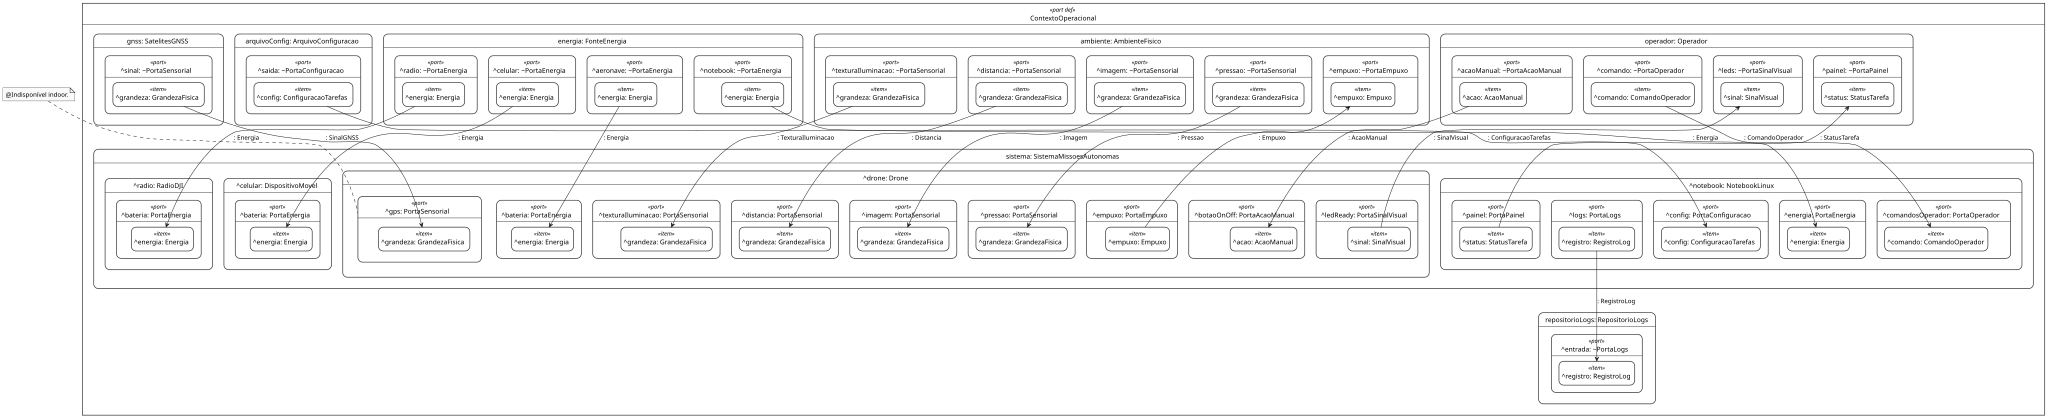

In [6]:
%viz --view=interconnection Nivel0::ContextoOperacional

### Nível 0 — componentes do sistema de missões

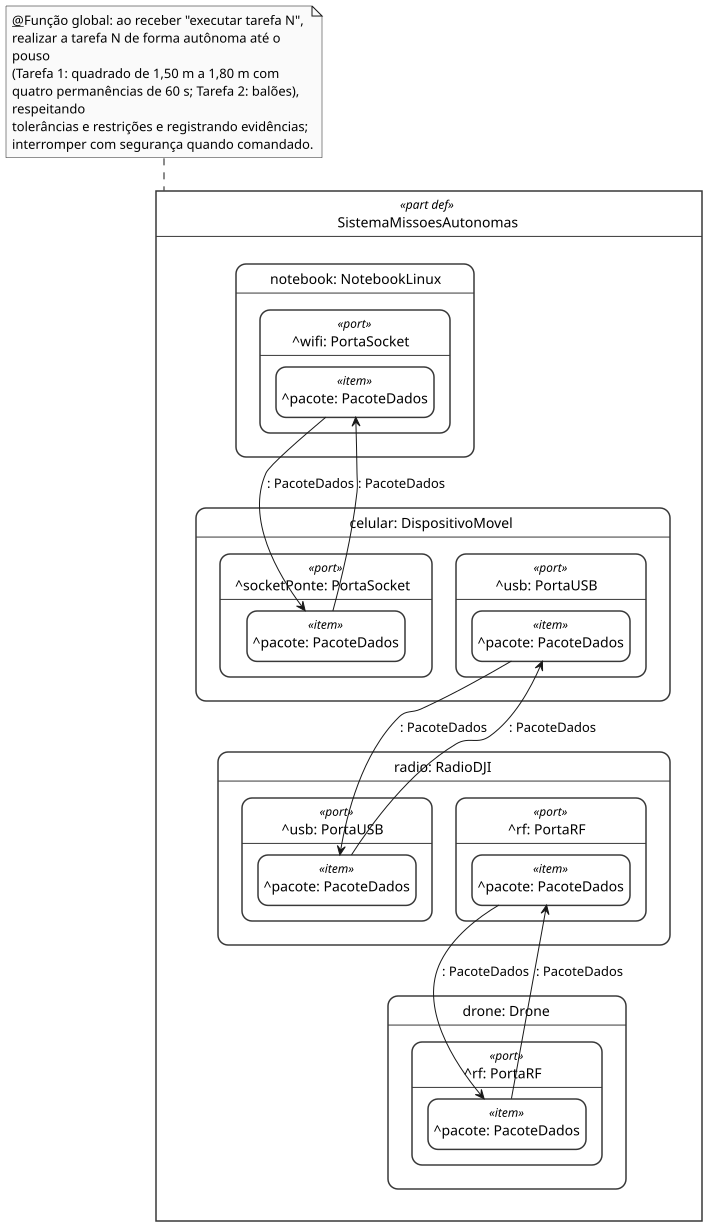

In [7]:
%viz --view=interconnection Nivel0::SistemaMissoesAutonomas

### Nível 0 — cenário de operação

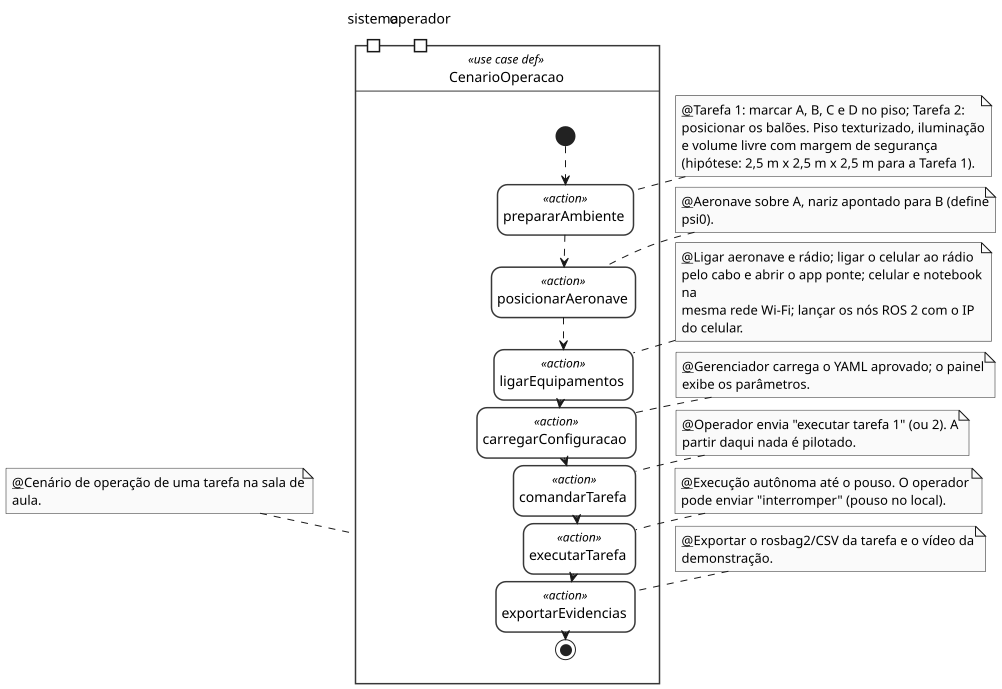

In [8]:
%viz --view=action Nivel0::CenarioOperacao

### Requisitos das Questões 1 e 2

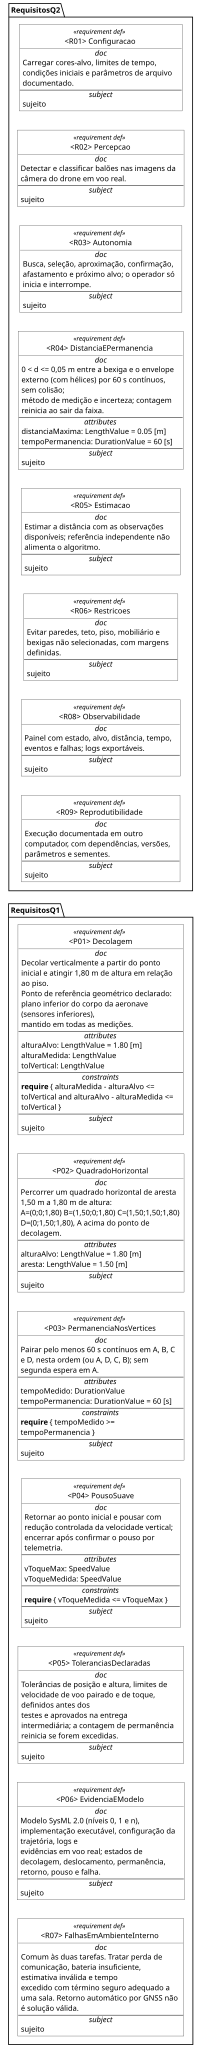

In [9]:
%viz --view=tree --style=LR Comum::RequisitosQ1 Comum::RequisitosQ2

### Nível 1 — nós ROS 2 e suas portas de tópico (pub = porta, sub = porta conjugada ~)

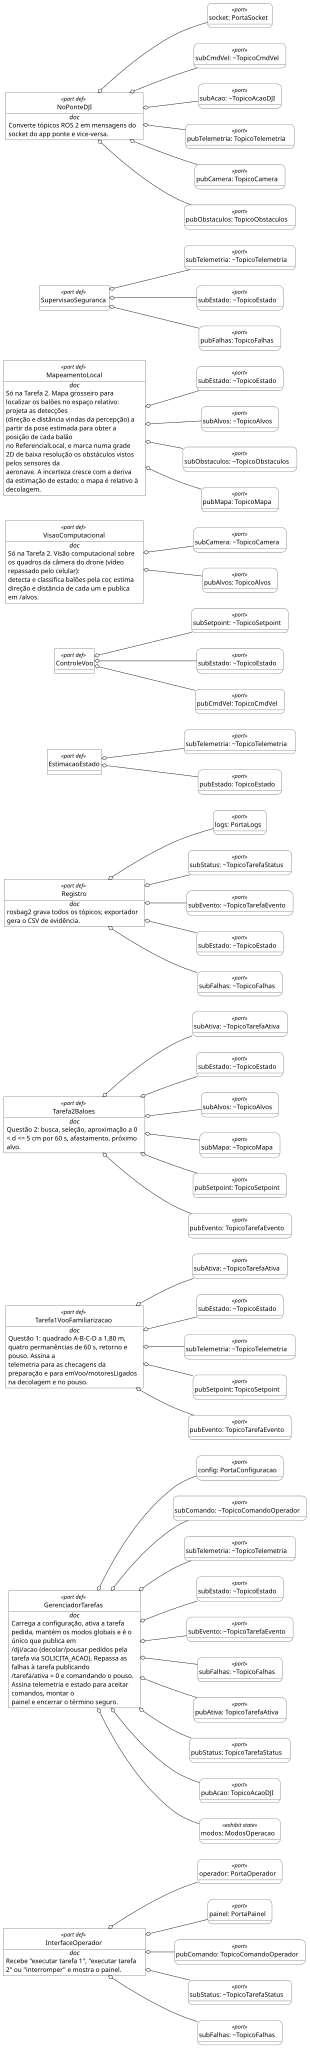

In [10]:
%viz --view=tree --style=LR Nivel1::InterfaceOperador Nivel1::GerenciadorTarefas Nivel1::Tarefa1VooFamiliarizacao Nivel1::Tarefa2Baloes Nivel1::Registro Nivel1::EstimacaoEstado Nivel1::ControleVoo Nivel1::VisaoComputacional Nivel1::MapeamentoLocal Nivel1::SupervisaoSeguranca Nivel1::NoPonteDJI

### Nível 1 — decomposição funcional da função global

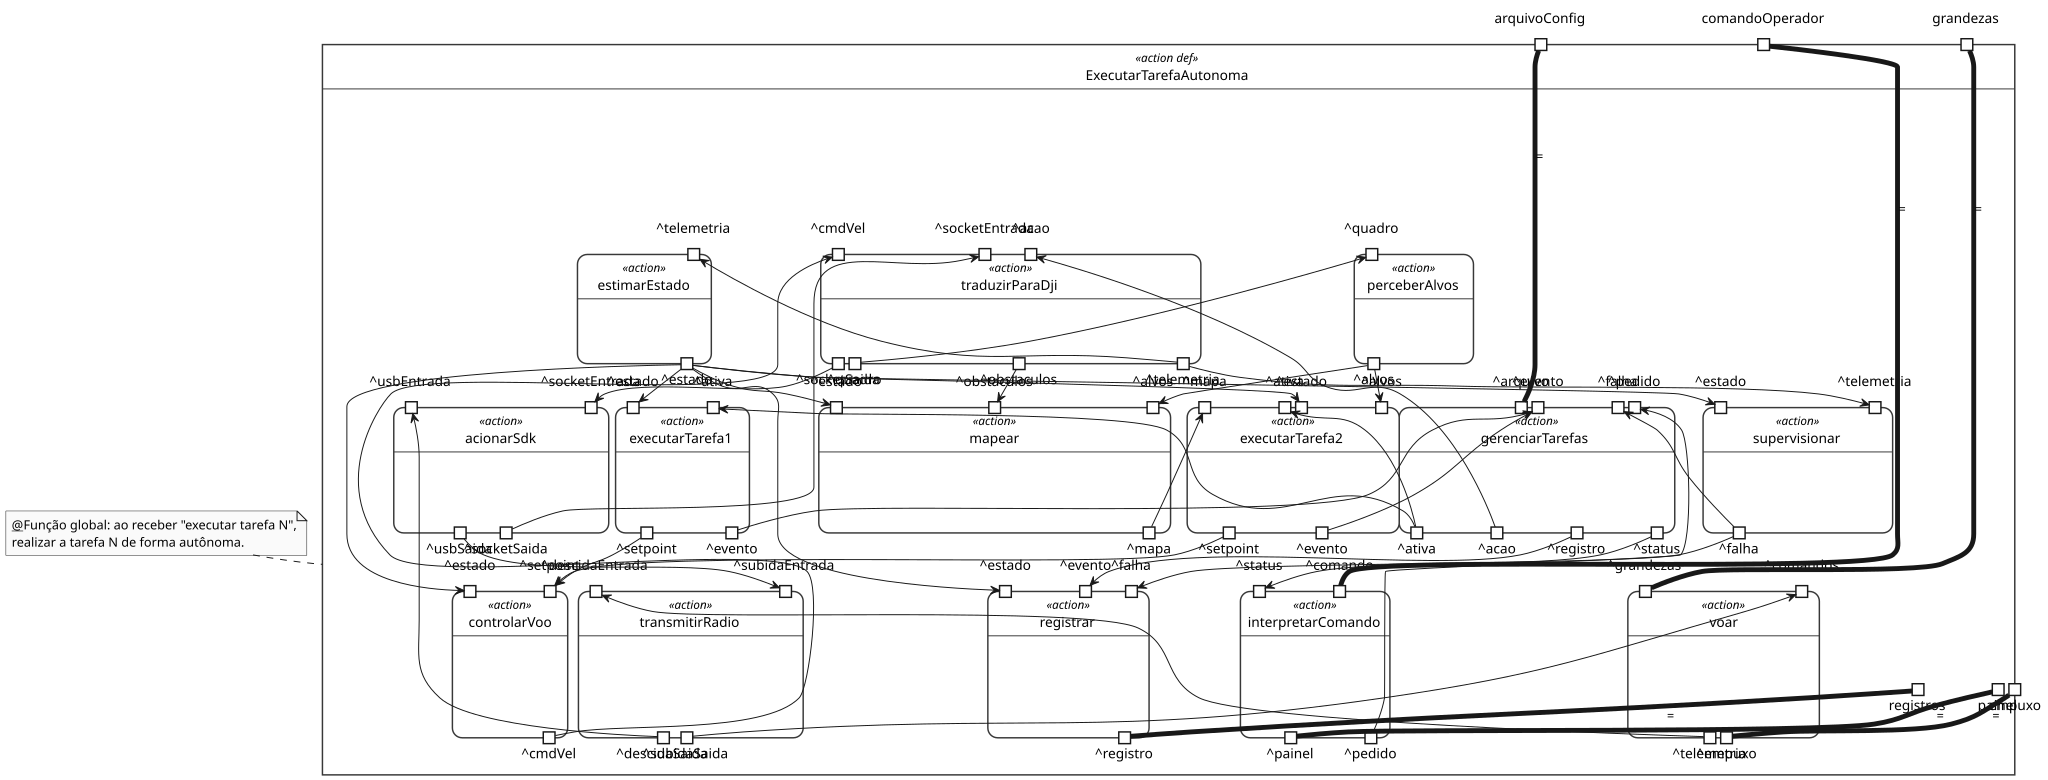

In [11]:
%viz --view=action Nivel1::ExecutarTarefaAutonoma

### Nível 1 — modos de operação (executar tarefa 1 / 2)

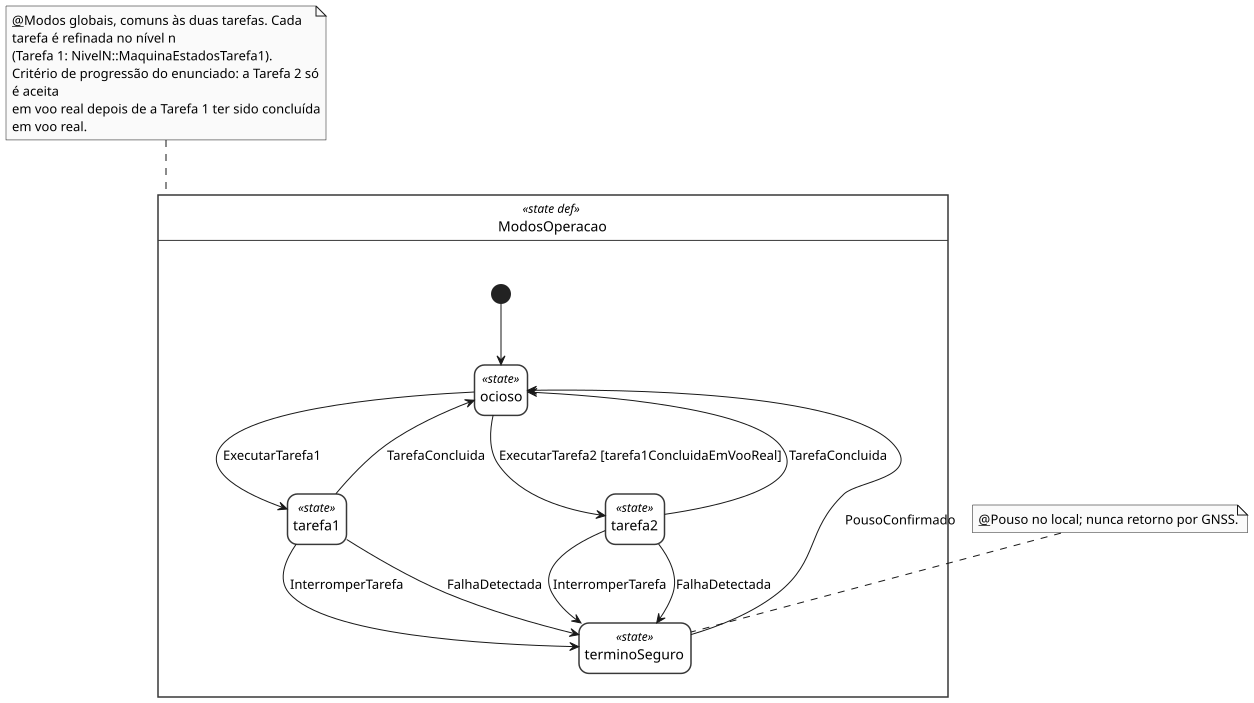

In [12]:
%viz --view=state Nivel1::ModosOperacao

### Nível n — drone caixa-preta explorado pelo SDK

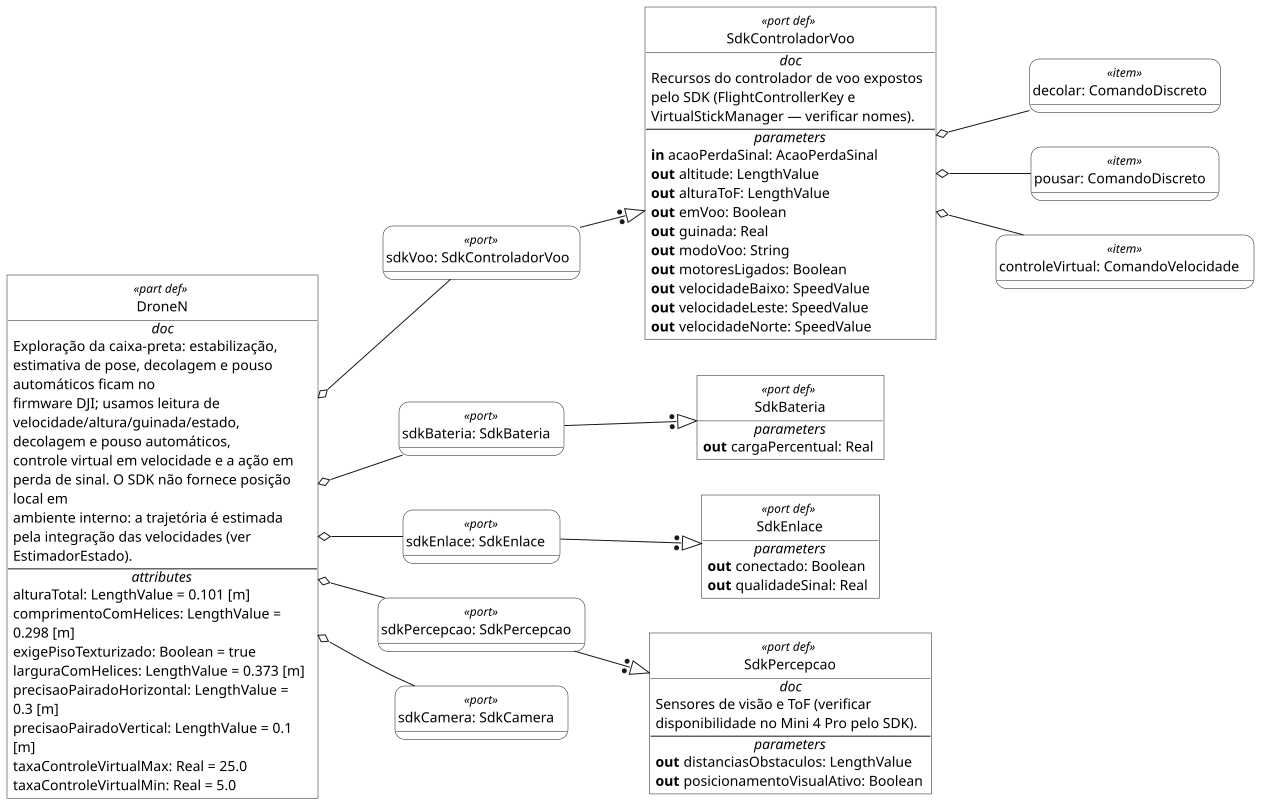

In [13]:
%viz --view=tree --style=LR NivelN::DroneN NivelN::SdkControladorVoo NivelN::SdkBateria NivelN::SdkEnlace NivelN::SdkPercepcao

### Nível n — módulos dos nós ROS 2

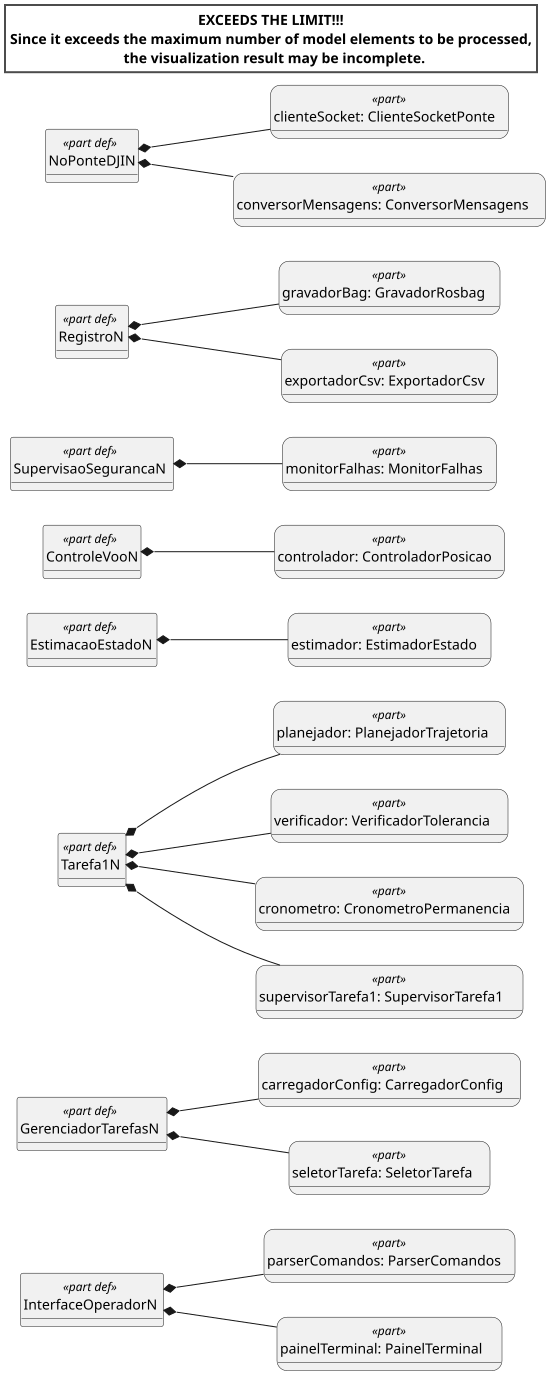

In [14]:
%viz --view=tree --style=LR NivelN::InterfaceOperadorN NivelN::GerenciadorTarefasN NivelN::Tarefa1N NivelN::EstimacaoEstadoN NivelN::ControleVooN NivelN::SupervisaoSegurancaN NivelN::RegistroN NivelN::NoPonteDJIN

### Nível n — módulos do app ponte (Android emulado)

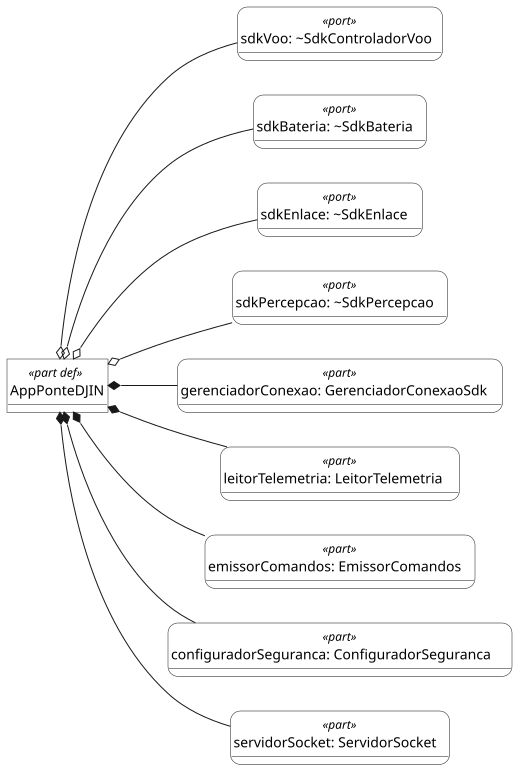

In [15]:
%viz --view=tree --style=LR NivelN::AppPonteDJIN

### Nível n — contratos de interface

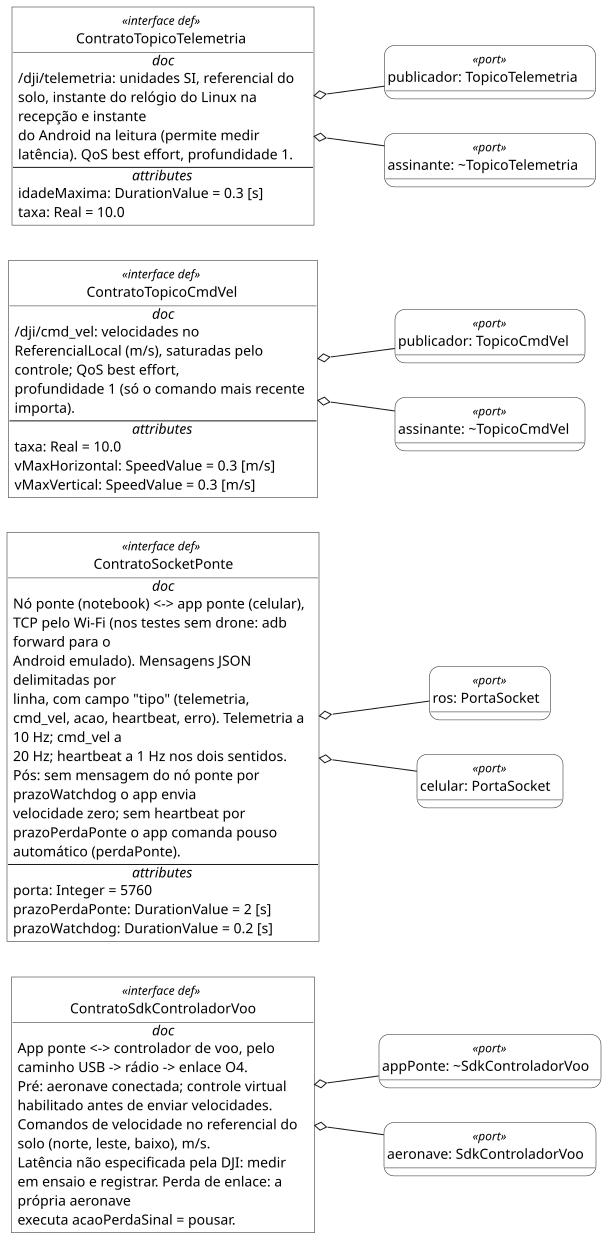

In [16]:
%viz --view=tree --style=LR NivelN::ContratoSdkControladorVoo NivelN::ContratoSocketPonte NivelN::ContratoTopicoCmdVel NivelN::ContratoTopicoTelemetria

### Nível n — máquina de estados da Tarefa 1 (P06)

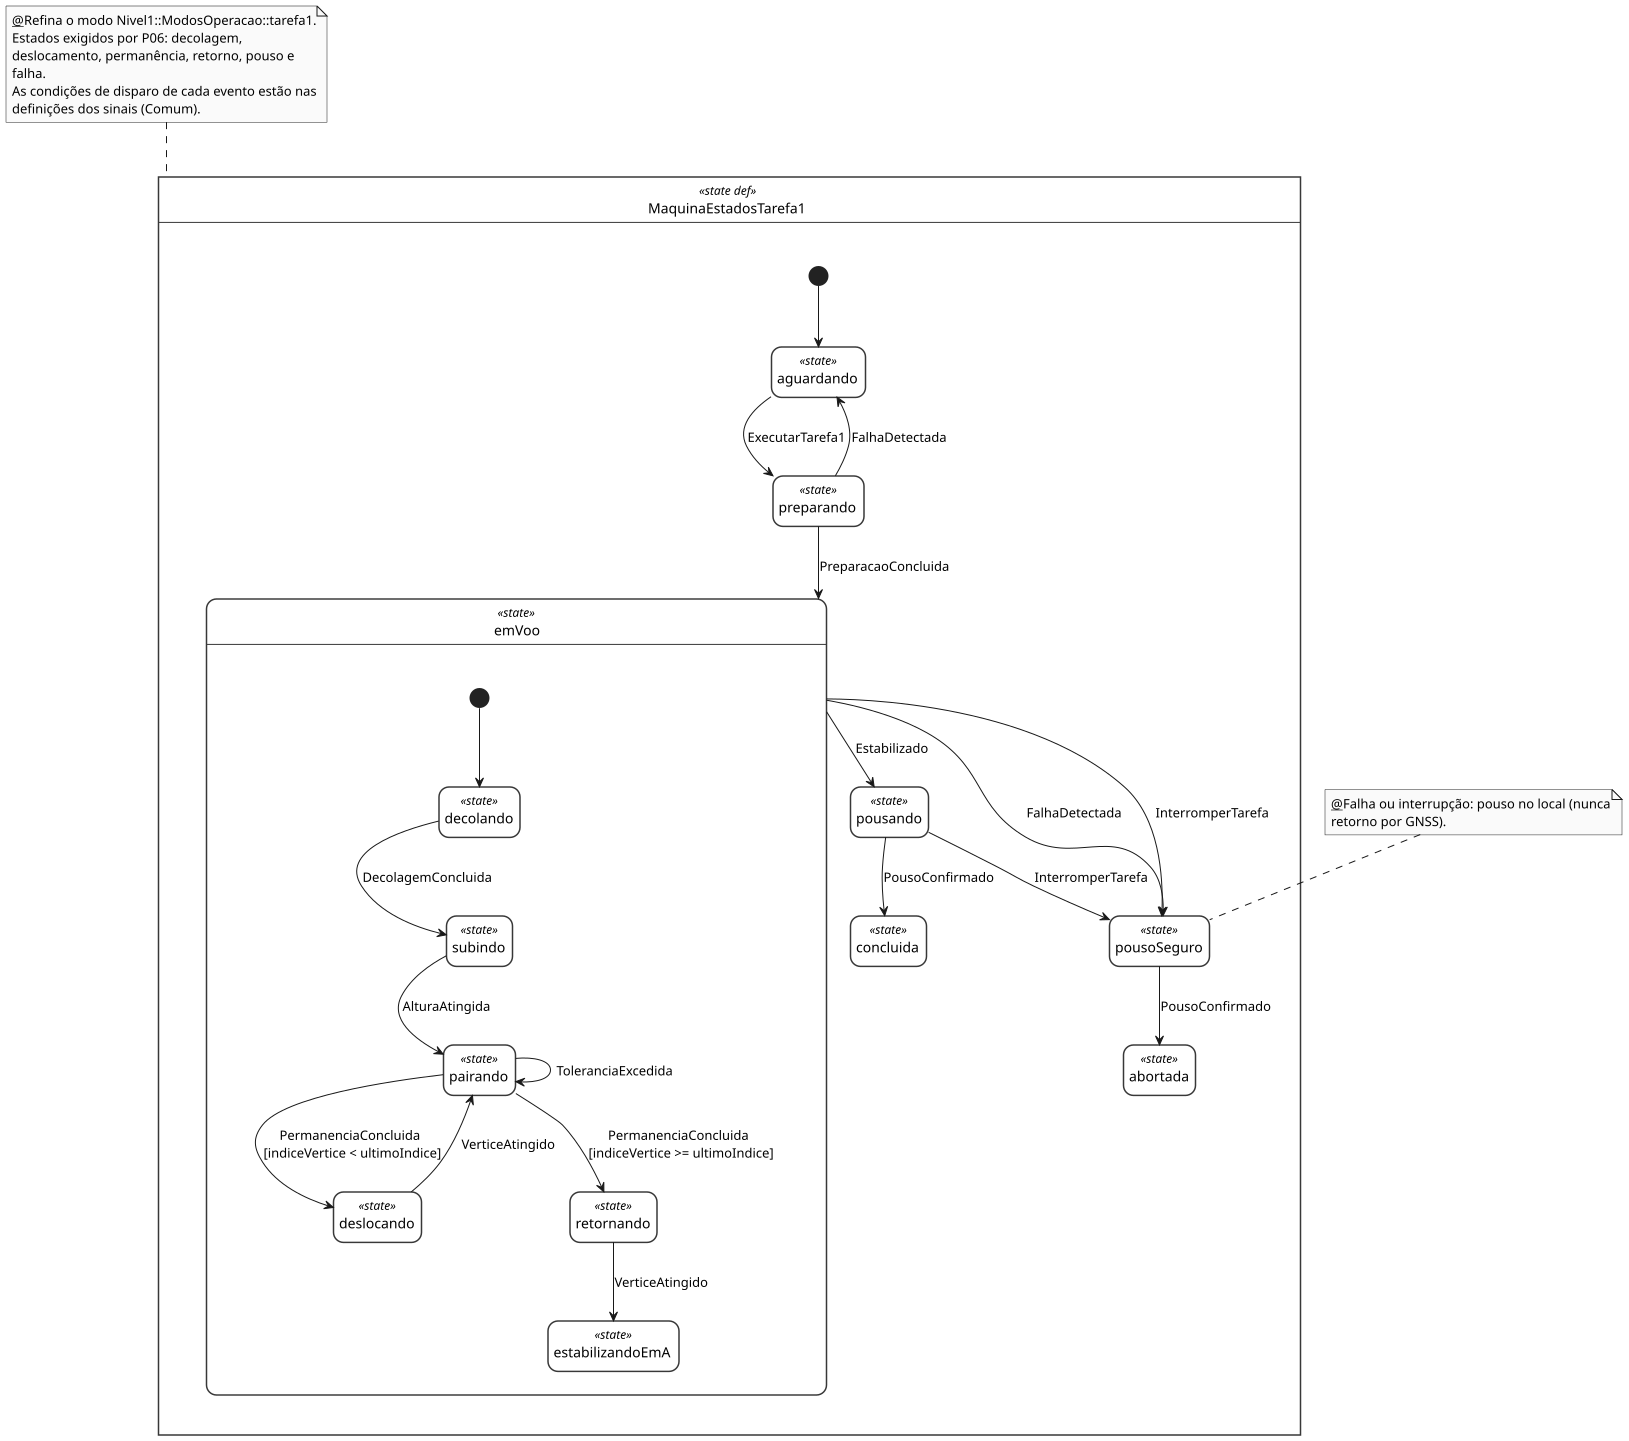

In [17]:
%viz --view=state NivelN::MaquinaEstadosTarefa1

### Nível n — ciclo de controle a 10 Hz

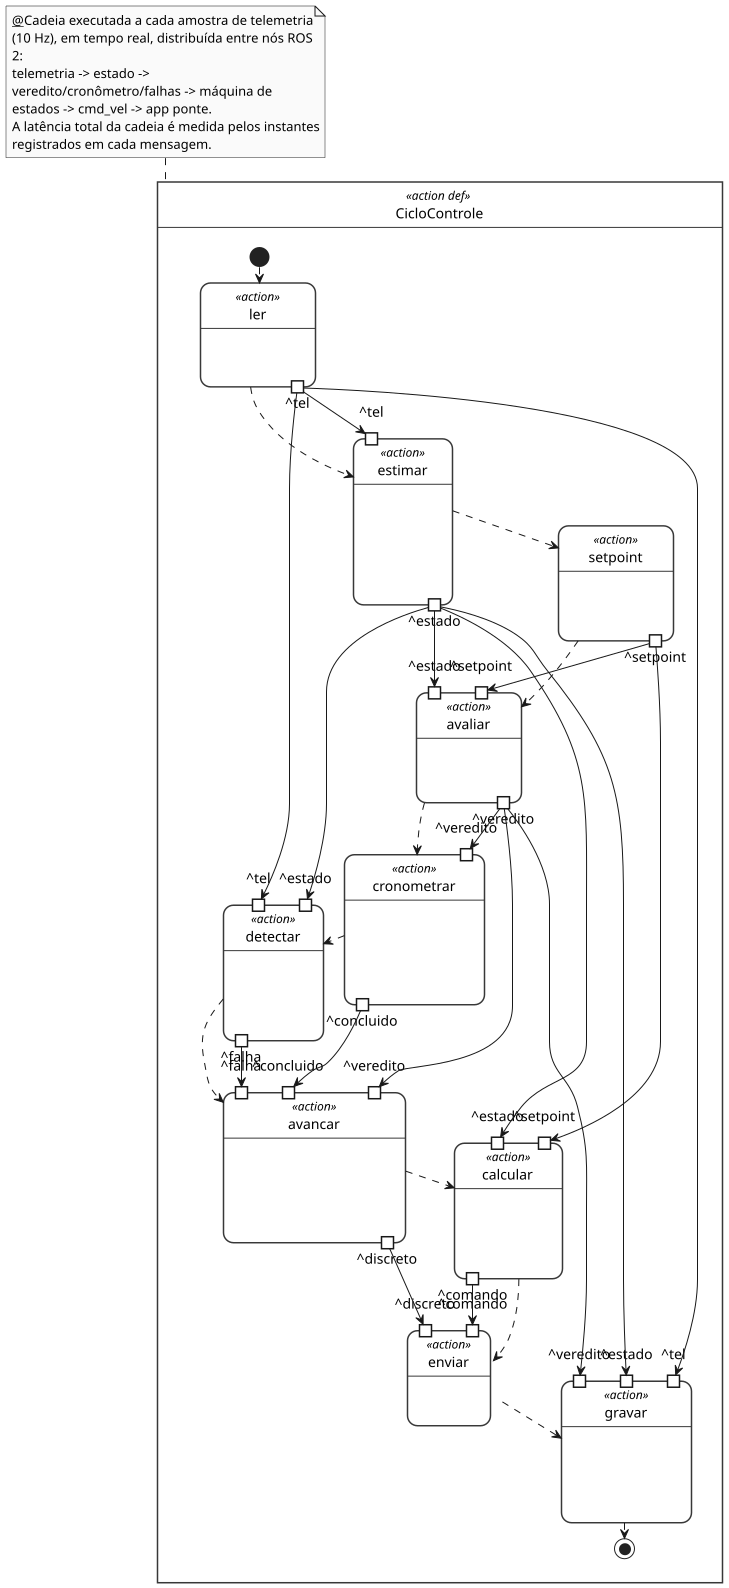

In [18]:
%viz --view=action NivelN::CicloControle

### Casos de verificação

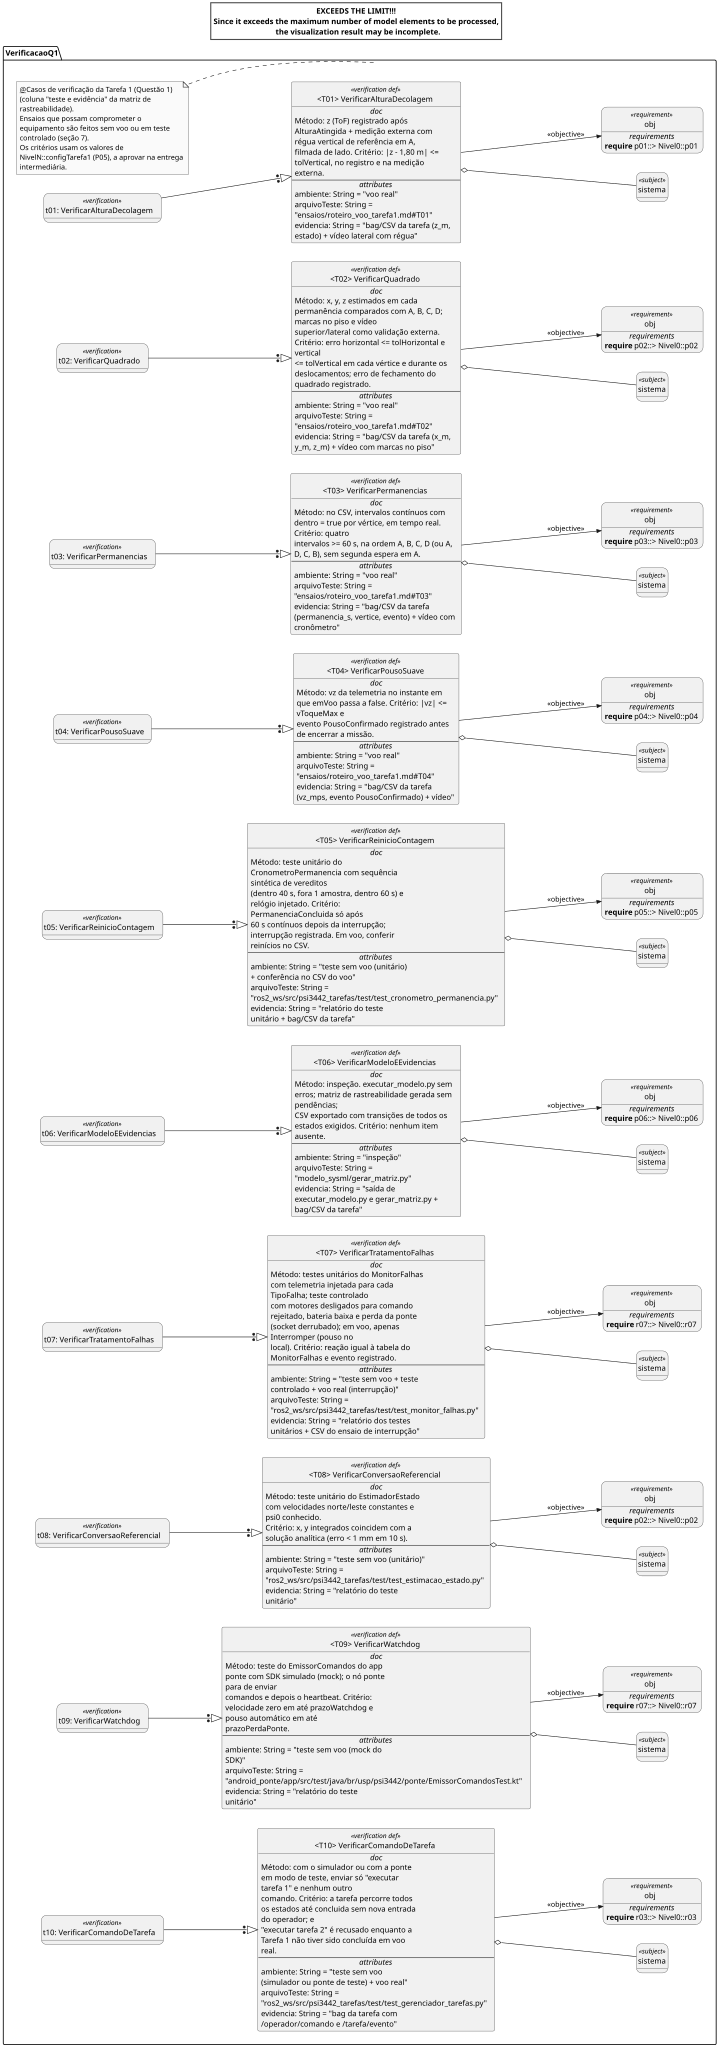

In [19]:
%viz --view=tree --style=LR VerificacaoQ1